### **Preprocessing Train Dataset**

In [1]:
import os
import gc
import joblib
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [2]:
import logging
from datetime import datetime

os.makedirs("logs", exist_ok=True)
logger = logging.getLogger("Merged-store-Predict-Models")
logger.setLevel(logging.INFO)

In [3]:
if not logger.handlers:

    # Log file with timestamp
    log_file = f"logs/  models_{datetime.now():%Y%m%d}.log"

    # File handler
    file_handler = logging.FileHandler(log_file, mode="a", encoding="utf-8")
    file_handler.setLevel(logging.INFO)

    # Console handler
    console_handler = logging.StreamHandler()
    console_handler.setLevel(logging.INFO)

    # Log format
    formatter = logging.Formatter(
        "%(asctime)s | %(levelname)s | %(message)s",
        datefmt="%Y-%m-%d %H:%M:%S"
    )

    file_handler.setFormatter(formatter)
    console_handler.setFormatter(formatter)

    logger.addHandler(file_handler)
    logger.addHandler(console_handler)

logger.info("=" * 70)
logger.info("CHECKING TRAINING DATA - MODELS LOGGING STARTED")
logger.info("=" * 70)


2026-11-15 03:59:56 | INFO | ======================================================================
2026-11-15 03:59:56 | INFO | CHECKING TRAINING DATA - MODELS LOGGING STARTED
2026-11-15 03:59:56 | INFO | ======================================================================


In [4]:
# Project paths
train_path = 'data/train_merged.csv'

# Load merged training dataset
train_df = pd.read_csv(train_path)

# Convert Date to datetime
train_df['Date'] = pd.to_datetime(
    train_df['Date'],
    errors='coerce'
)

print("Training dataset shape:", train_df.shape)
print("\nDataset columns:")
print(train_df.columns.tolist())

print("\nDataset information:")
train_df.info()

print("\nFirst five records:")
display(train_df.head())

print("\nMissing values:")
print(
    train_df.isnull().sum()
    .sort_values(ascending=False)
    .head(15)
)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_20068\471001633.py:5: DtypeWarning: Columns (0: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  train_df = pd.read_csv(train_path)


Training dataset shape: (1017209, 24)

Dataset columns:
['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsWeekend', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'CompetitionDateMissing']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 24 columns):
 #   Column                     Non-Null Count    Dtype         
---  ------                     --------------    -----         
 0   Store                      1017209 non-null  int64         
 1   DayOfWeek                  1017209 non-null  int64         
 2   Date                       1017209 non-null  datetime64[us]
 3   Sales                      1017209 non-null  int64         
 4   Customers                  1017209 non-null  int64         
 5   Open    

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,Year,...,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionDateMissing
0,1,5,2015-07-31,5263,555,1,1,0,1,2015,...,c,a,1270.0,9.0,2008.0,0,0.0,0.0,NoPromo2,0
1,2,5,2015-07-31,6064,625,1,1,0,1,2015,...,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct",0
2,3,5,2015-07-31,8314,821,1,1,0,1,2015,...,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",0
3,4,5,2015-07-31,13995,1498,1,1,0,1,2015,...,c,c,620.0,9.0,2009.0,0,0.0,0.0,NoPromo2,0
4,5,5,2015-07-31,4822,559,1,1,0,1,2015,...,a,a,16107.5,4.0,2015.0,0,0.0,0.0,NoPromo2,0



Missing values:
Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
Year             0
Month            0
Day              0
WeekOfYear       0
IsWeekend        0
StoreType        0
dtype: int64


In [5]:
from io import StringIO

buffer = StringIO()
train_df.info(buf=buffer)

logger.info("=" * 70)
logger.info("CHECKING TRAINING DATA")
logger.info("=" * 70)

# Project paths
train_path = 'data/train_merged.csv'

logger.info("Training dataset path: %s", train_path)

# Load merged training dataset
train_df = pd.read_csv(train_path)

logger.info("Training dataset loaded successfully.")
logger.info("Training dataset shape: %s", train_df.shape)
logger.info("Total rows: %d", train_df.shape[0])
logger.info("Total columns: %d", train_df.shape[1])

# Convert Date to datetime
train_df['Date'] = pd.to_datetime(
    train_df['Date'],
    errors='coerce'
)

logger.info("Date column converted to datetime.")
logger.info(
    "Invalid or missing dates after conversion: %d",
    train_df['Date'].isna().sum()
)

# Dataset columns
logger.info("Training dataset columns: %s", train_df.columns.tolist())

# Dataset information
logger.info("Training dataset information:")
logger.info("\n%s", buffer.getvalue())

# First five records
logger.info("First five records of training dataset:")
display(train_df.head())

# Missing values
missing_values = (
    train_df.isnull()
    .sum()
    .sort_values(ascending=False)
)

logger.info("Missing value analysis completed.")
logger.info(
    "Top 15 columns with missing values:\n%s",
    missing_values.head(15).to_string()
)

logger.info("Total missing values in training dataset: %d",
            missing_values.sum())

2026-11-15 04:00:03 | INFO | ======================================================================
2026-11-15 04:00:03 | INFO | CHECKING TRAINING DATA
2026-11-15 04:00:03 | INFO | ======================================================================
2026-11-15 04:00:03 | INFO | Training dataset path: data/train_merged.csv
C:\Users\ASUS\AppData\Local\Temp\ipykernel_20068\495077160.py:16: DtypeWarning: Columns (0: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  train_df = pd.read_csv(train_path)
2026-11-15 04:00:08 | INFO | Training dataset loaded successfully.
2026-11-15 04:00:08 | INFO | Training dataset shape: (1017209, 24)
2026-11-15 04:00:08 | INFO | Total rows: 1017209
2026-11-15 04:00:08 | INFO | Total columns: 24
2026-11-15 04:00:09 | INFO | Date column converted to datetime.
2026-11-15 04:00:09 | INFO | Invalid or missing dates after conversion: 0
2026-11-15 04:00:09 | INFO | Training dataset columns: ['Store', 'DayOfWeek', 'Date', 'Sa

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,Year,...,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionDateMissing
0,1,5,2015-07-31,5263,555,1,1,0,1,2015,...,c,a,1270.0,9.0,2008.0,0,0.0,0.0,NoPromo2,0
1,2,5,2015-07-31,6064,625,1,1,0,1,2015,...,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct",0
2,3,5,2015-07-31,8314,821,1,1,0,1,2015,...,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",0
3,4,5,2015-07-31,13995,1498,1,1,0,1,2015,...,c,c,620.0,9.0,2009.0,0,0.0,0.0,NoPromo2,0
4,5,5,2015-07-31,4822,559,1,1,0,1,2015,...,a,a,16107.5,4.0,2015.0,0,0.0,0.0,NoPromo2,0


2026-11-15 04:00:09 | INFO | Missing value analysis completed.
2026-11-15 04:00:09 | INFO | Top 15 columns with missing values:
Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
Year             0
Month            0
Day              0
WeekOfYear       0
IsWeekend        0
StoreType        0
2026-11-15 04:00:09 | INFO | Total missing values in training dataset: 0


In [6]:
# Verify target column
if 'Sales' not in train_df.columns:
    raise ValueError("Sales target column is missing.")

# Verify date column
if train_df['Date'].isnull().any():
    raise ValueError("Invalid or missing Date values found.")

print("Working dataset shape:", train_df.shape)

Working dataset shape: (1017209, 24)


## 💨 Training Dataset Overview

The prepared working dataset contains **1,017,209 records and 24 columns**, including the target variable `Sales`.

| **Dataset Attribute** | **Details** |
|:--|--:|
| Total Records | 1,017,209 |
| Total Features | 24 |
| Target Variable | `Sales` |
| Dataset Type | Training Dataset |

### Key Observations

- The dataset contains over **1 million store-day observations**, providing substantial data for model development.
- All 24 columns are available for further preprocessing and feature engineering.
- The target variable `Sales` is available for supervised learning.

**Next Step:** Inspect data types, missing values, duplicate records, and target distribution before proceeding with feature engineering and model training.

In [7]:
logger.info("=" * 70)
logger.info("TRAINING DATA VALIDATION")
logger.info("=" * 70)

# Verify target column
logger.info("Checking whether Sales target column exists.")

if 'Sales' not in train_df.columns:

    logger.error("Sales target column is missing.")

logger.info("Sales target column verified successfully.")

# Verify date column
logger.info("Checking for invalid or missing Date values.")

invalid_dates = train_df['Date'].isnull().sum()

if invalid_dates > 0:

    logger.error(
        "Found %d invalid or missing Date values.",
        invalid_dates
    )

logger.info("Date column validation completed successfully.")
logger.info("No invalid or missing Date values found.")

# Working dataset information
logger.info("Working dataset shape: %s", train_df.shape)
logger.info("Total training records: %d", len(train_df))

2026-11-15 04:00:09 | INFO | ======================================================================
2026-11-15 04:00:09 | INFO | TRAINING DATA VALIDATION
2026-11-15 04:00:09 | INFO | ======================================================================
2026-11-15 04:00:09 | INFO | Checking whether Sales target column exists.
2026-11-15 04:00:09 | INFO | Sales target column verified successfully.
2026-11-15 04:00:09 | INFO | Checking for invalid or missing Date values.
2026-11-15 04:00:09 | INFO | Date column validation completed successfully.
2026-11-15 04:00:09 | INFO | No invalid or missing Date values found.
2026-11-15 04:00:09 | INFO | Working dataset shape: (1017209, 24)
2026-11-15 04:00:09 | INFO | Total training records: 1017209


In [8]:
# Month period
train_df['MonthPeriod'] = np.select(
    [
        train_df['Day'].between(1, 10),
        train_df['Day'].between(11, 20),
        train_df['Day'].between(21, 31)
    ],
    [
        'Beginning',
        'Middle',
        'End'
    ],
    default='Unknown'
)

# Additional month features

print(
    train_df[
        ['Date', 'Year', 'Month', 'Day',
         'MonthPeriod']
    ].head(10)
)

        Date  Year  Month  Day MonthPeriod
0 2015-07-31  2015      7   31         End
1 2015-07-31  2015      7   31         End
2 2015-07-31  2015      7   31         End
3 2015-07-31  2015      7   31         End
4 2015-07-31  2015      7   31         End
5 2015-07-31  2015      7   31         End
6 2015-07-31  2015      7   31         End
7 2015-07-31  2015      7   31         End
8 2015-07-31  2015      7   31         End
9 2015-07-31  2015      7   31         End


## 🕵️‍♀️ Feature Engineering – Monthly Period Segmentation

Create a categorical feature, `MonthPeriod`, to capture potential differences in sales behaviour across different parts of a month.

### 🔧 Methodology

The `Day` feature is divided into three monthly segments:

| **Month Period** | **Day Range** |
|:--|:--|
| Beginning | 1–10 |
| Middle | 11–20 |
| End | 21–31 |

The new feature is generated using conditional selection and added to the training dataset.

### Key Insights

- **Beginning:** Represents the first ten days of each month.
- **Middle:** Captures the middle ten days.
- **End:** Represents the remaining days of the month.
- The new categorical feature may help identify sales variations associated with different monthly periods.

**Next Step:** Examine sales distribution across the three segments to determine whether monthly purchasing patterns provide useful predictive information.

In [9]:
# MONTH PERIOD FEATURE - LOGGING

logger.info("=" * 70)
logger.info("MONTH PERIOD FEATURE ENGINEERING")
logger.info("=" * 70)

logger.info(
    "MonthPeriod distribution:\n%s",
    train_df['MonthPeriod'].value_counts().to_string()
)

logger.info(
    "MonthPeriod missing values: %d",
    train_df['MonthPeriod'].isnull().sum()
)

logger.info(
    "MonthPeriod unique categories: %s",
    train_df['MonthPeriod'].unique().tolist()
)

logger.info(
    "Date-wise month feature sample:\n%s",
    train_df[
        ['Date', 'Year', 'Month', 'Day', 'MonthPeriod']
    ].head(10).to_string(index=False)
)

2026-11-15 04:00:10 | INFO | ======================================================================
2026-11-15 04:00:10 | INFO | MONTH PERIOD FEATURE ENGINEERING
2026-11-15 04:00:10 | INFO | ======================================================================
2026-11-15 04:00:10 | INFO | MonthPeriod distribution:
MonthPeriod
End          347510
Middle       334850
Beginning    334849
2026-11-15 04:00:10 | INFO | MonthPeriod missing values: 0
2026-11-15 04:00:10 | INFO | MonthPeriod unique categories: ['End', 'Middle', 'Beginning']
2026-11-15 04:00:10 | INFO | Date-wise month feature sample:
      Date  Year  Month  Day MonthPeriod
2015-07-31  2015      7   31         End
2015-07-31  2015      7   31         End
2015-07-31  2015      7   31         End
2015-07-31  2015      7   31         End
2015-07-31  2015      7   31         End
2015-07-31  2015      7   31         End
2015-07-31  2015      7   31         End
2015-07-31  2015      7   31         End
2015-07-31  2015      7   31   

In [10]:
# Separate target
y = train_df['Sales'].copy()

# Columns that must not be used as model features
excluded_features = [
    'Sales',       # Target variable
    'Customers',   # Not available in test dataset
    'Date',        # Original date retained for reference
    'Id'           # Identifier, if present
]

# Create feature dataset
X = train_df.drop(
    columns=[
        col for col in excluded_features
        if col in train_df.columns
    ]
).copy()

# Treat Store as a categorical identifier
X['Store'] = X['Store'].astype(str)

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget summary:")
print(y.describe())

Input feature shape: (1017209, 22)
Target shape: (1017209,)

Target summary:
count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64


## 🍝 Target Separation & Feature Selection

The target variable `Sales` was separated from the training dataset to establish the supervised learning structure.

The following columns were excluded from the model input:

| **Feature** | **Reason for Exclusion** |
|:--|:--|
| `Sales` | Target variable to be predicted |
| `Customers` | Not available in the test dataset; prevents prediction-time data mismatch |
| `Date` | Original date retained for reference; engineered date features are used instead |
| `Id` | Identifier without direct predictive significance |

Additionally, `Store` was converted into a categorical (`string`) data type to represent individual store identities.

### 🔑 Key Observations

- **Large Training Sample:** Over 1 million observations are available for model development.
- **Sales Distribution:** Mean sales (5,773.82) are slightly higher than median sales (5,744), indicating mild right-skewness.
- **High Variability:** The standard deviation of 3,849.93 indicates considerable variation in daily store sales.
- **Zero Sales:** The minimum sales value is zero, which may represent closed-store days or other zero-sales observations.
- **Prediction Consistency:** Excluding `Customers` ensures that the model relies only on features available in the test dataset.

**Next Step:** Examine the target distribution and feature relationships to identify suitable transformations, preprocessing requirements, and modelling strategies.

In [11]:
# ============================================================
# FEATURE AND TARGET SEPARATION - LOGGING
# ============================================================

logger.info("=" * 70)
logger.info("FEATURE AND TARGET SEPARATION")
logger.info("=" * 70)

logger.info("Target variable extracted successfully: Sales")
logger.info("Excluded features: %s", excluded_features)

logger.info("Input feature shape: %s", X.shape)
logger.info("Target shape: %s", y.shape)

logger.info("Input feature columns: %s", X.columns.tolist())

logger.info(
    "Store column converted to categorical string type."
)

logger.info(
    "Store unique count: %d",
    X['Store'].nunique()
)

logger.info(
    "Target variable summary statistics:\n%s",
    y.describe().to_string()
)

logger.info(
    "Missing values in input features: %d",
    X.isnull().sum().sum()
)

logger.info(
    "Missing values in target variable: %d",
    y.isnull().sum()
)

2026-11-15 04:00:11 | INFO | ======================================================================
2026-11-15 04:00:11 | INFO | FEATURE AND TARGET SEPARATION
2026-11-15 04:00:11 | INFO | ======================================================================
2026-11-15 04:00:11 | INFO | Target variable extracted successfully: Sales
2026-11-15 04:00:11 | INFO | Excluded features: ['Sales', 'Customers', 'Date', 'Id']
2026-11-15 04:00:11 | INFO | Input feature shape: (1017209, 22)
2026-11-15 04:00:11 | INFO | Target shape: (1017209,)
2026-11-15 04:00:11 | INFO | Input feature columns: ['Store', 'DayOfWeek', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsWeekend', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'CompetitionDateMissing', 'MonthPeriod']
2026-11-15 04:00:11 | INFO | Store column converted to categorical string 

In [12]:
# Identify categorical features
categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

# Identify numerical features
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

print("\nTotal categorical features:", len(categorical_features))
print("Total numerical features:", len(numerical_features))

Categorical features:
['Store', 'StateHoliday', 'StoreType', 'Assortment', 'PromoInterval', 'MonthPeriod']

Numerical features:
['DayOfWeek', 'Open', 'Promo', 'SchoolHoliday', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsWeekend', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'CompetitionDateMissing']

Total categorical features: 6
Total numerical features: 16


C:\Users\ASUS\AppData\Local\Temp\ipykernel_20068\262095925.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [13]:
# Numerical preprocessing
numerical_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

# Categorical preprocessing
categorical_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(
              handle_unknown='use_encoded_value',
            unknown_value=-1
        ))
    ]
)

# Combine both pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ('numerical', numerical_pipeline, numerical_features),
        ('categorical', categorical_pipeline, categorical_features)
    ],
    remainder='drop',
    verbose_feature_names_out=True
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## 🖇️ Data Preprocessing – Numerical & Categorical Pipelines

Develop a unified preprocessing pipeline to handle missing values, scale numerical features, and encode categorical variables before model training.

### 🧑‍🔧 Preprocessing Methodology

| **Feature Type** | **Preprocessing Technique** | **Purpose** |
|:--|:--|:--|
| Numerical | Median Imputation | Handle missing numerical values |
| Numerical | Standard Scaling | Standardise features to a common scale |
| Categorical | Most Frequent Imputation | Handle missing categorical values |
| Categorical | Ordinal Encoding | Convert categorical values into numerical representations |
| Unknown Categories | Value `-1` | Handle previously unseen categories during prediction |

### 🚅 Pipeline Architecture

- **Numerical Pipeline:** Missing values are replaced using the median, followed by standardisation using `StandardScaler`.
- **Categorical Pipeline:** Missing values are replaced using the most frequent category, followed by `OrdinalEncoder`.
- **Column Transformer:** Combines both pipelines and applies the appropriate transformations to their respective feature groups.
- **Remainder Handling:** Unspecified columns are dropped to ensure only selected numerical and categorical features are processed.

### ㊗️ Key Considerations

- Unknown categorical values are encoded as `-1`, preventing errors when unseen categories occur in the test dataset.

**Next Step:** Integrate the preprocessing pipeline with the selected regression models and fit it using the training data. Ensure the preprocessing parameters are learned only from the training split to avoid data leakage.

In [14]:
logger.info("=" * 70)
logger.info("PREPROCESSING PIPELINE CREATION")
logger.info("=" * 70)

# Numerical pipeline
logger.info("Numerical preprocessing pipeline created.")
logger.info("Numerical imputation strategy: Median")
logger.info("Numerical scaling technique: StandardScaler")

logger.info(
    "Numerical features (%d): %s",
    len(numerical_features),
    numerical_features
)

# Categorical pipeline
logger.info("Categorical preprocessing pipeline created.")
logger.info("Categorical imputation strategy: Most Frequent")
logger.info("Categorical encoding technique: OrdinalEncoder")
logger.info("Unknown category handling: Encoded as -1")

logger.info(
    "Categorical features (%d): %s",
    len(categorical_features),
    categorical_features
)

# Combined preprocessor
logger.info("ColumnTransformer created successfully.")
logger.info("Remainder strategy: drop")
logger.info(
    "Total features configured for preprocessing: %d",
    len(numerical_features) + len(categorical_features)
)

2026-11-15 04:00:11 | INFO | ======================================================================
2026-11-15 04:00:11 | INFO | PREPROCESSING PIPELINE CREATION
2026-11-15 04:00:11 | INFO | ======================================================================
2026-11-15 04:00:11 | INFO | Numerical preprocessing pipeline created.
2026-11-15 04:00:11 | INFO | Numerical imputation strategy: Median
2026-11-15 04:00:11 | INFO | Numerical scaling technique: StandardScaler
2026-11-15 04:00:11 | INFO | Numerical features (16): ['DayOfWeek', 'Open', 'Promo', 'SchoolHoliday', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsWeekend', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'CompetitionDateMissing']
2026-11-15 04:00:11 | INFO | Categorical preprocessing pipeline created.
2026-11-15 04:00:11 | INFO | Categorical imputation strategy: Most Frequent
2026-11-15 04:00:11 | INFO | Categorical encoding technique: OrdinalEnco

In [15]:
# Check categorical columns for mixed data types
for col in categorical_features:
    types = X[col].dropna().apply(type).unique()

    if len(types) > 1:
        print(f"{col}: {types}")

StateHoliday: [<class 'int'> <class 'str'>]


## 🚥 Categorical Feature Validation – Mixed Data Type Check

Verify whether categorical features contain inconsistent data types before applying the encoding pipeline.

### 🧰 Methodology
- Iterated through all selected categorical features.
- Excluded missing values during inspection.
- Identified the unique Python data types present in each column.
- Displayed only columns containing more than one data type.

This validation helps identify potential inconsistencies, such as numerical and string values coexisting within the same categorical column.

**Result Interpretation:**
- If no columns are printed, all inspected categorical features have consistent data types.
- If any column is displayed, its mixed data types should be standardised before encoding.

**Next Step:** Resolve any identified type inconsistencies and proceed with categorical preprocessing.

In [16]:
# Convert categorical features into consistent string format
for col in categorical_features:
    X[col] = X[col].astype('string')

In [17]:
# Fit and transform training features
X_processed = preprocessor.fit_transform(X)

print("Original feature shape:", X.shape)
print("Processed feature shape:", X_processed.shape)

print("\nPreprocessing completed successfully.")

Original feature shape: (1017209, 22)
Processed feature shape: (1017209, 22)

Preprocessing completed successfully.


## 🧑‍🏭 Feature Preprocessing – Execution & Validation

Apply the combined preprocessing pipeline to transform numerical and categorical features into a model-ready format.

| **Metric** | **Original Dataset** | **Processed Dataset** |
|:--|--:|--:|
| Total Records | 1,017,209 | 1,017,209 |
| Total Features | 22 | 22 |

### 🔍 Key Observations

- **Shape Consistency:** The number of records and features remains unchanged after preprocessing.
- **Successful Transformation:** Numerical scaling, missing-value imputation, and categorical encoding were executed successfully.
- **Model Readiness:** All 22 selected features have been transformed into a numerical representation suitable for machine learning algorithms.

*Note: The unchanged shape confirms dimensional consistency, but does not independently verify that missing values and invalid numerical values have been fully resolved.*

In [18]:
logger.info("=" * 70)
logger.info("TRAINING DATA PREPROCESSING")
logger.info("=" * 70)

logger.info("Preprocessing pipeline fitted successfully.")
logger.info("Training features transformed successfully.")

logger.info("Original feature shape: %s", X.shape)
logger.info("Processed feature shape: %s", X_processed.shape)

logger.info(
    "Original feature count: %d",
    X.shape[1]
)

logger.info(
    "Processed feature count: %d",
    X_processed.shape[1]
)

logger.info(
    "Processed training data contains NaN values: %s",
    np.isnan(X_processed).any()
)

2026-11-15 04:00:25 | INFO | ======================================================================
2026-11-15 04:00:25 | INFO | TRAINING DATA PREPROCESSING
2026-11-15 04:00:25 | INFO | ======================================================================
2026-11-15 04:00:25 | INFO | Preprocessing pipeline fitted successfully.
2026-11-15 04:00:25 | INFO | Training features transformed successfully.
2026-11-15 04:00:25 | INFO | Original feature shape: (1017209, 22)
2026-11-15 04:00:25 | INFO | Processed feature shape: (1017209, 22)
2026-11-15 04:00:25 | INFO | Original feature count: 22
2026-11-15 04:00:25 | INFO | Processed feature count: 22
2026-11-15 04:00:26 | INFO | Processed training data contains NaN values: False


### **Preprocessing Test Dataset**

In [19]:
# Project paths
test_path = 'data/test_merged.csv'

# Load merged testing dataset
test_df = pd.read_csv(test_path)

# Convert Date to datetime
test_df['Date'] = pd.to_datetime(
    test_df['Date'],
    errors='coerce'
)

print("testing dataset shape:", test_df.shape)
print("\nDataset columns:")
print(test_df.columns.tolist())

print("\nDataset information:")
test_df.info()

print("\nFirst five records:")
display(test_df.head())

print("\nMissing values:")
print(
    test_df.isnull().sum()
    .sort_values(ascending=False)
    .head(15)
)

testing dataset shape: (41088, 23)

Dataset columns:
['Id', 'Store', 'DayOfWeek', 'Date', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsWeekend', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'CompetitionDateMissing']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 41088 entries, 0 to 41087
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Id                         41088 non-null  int64         
 1   Store                      41088 non-null  int64         
 2   DayOfWeek                  41088 non-null  int64         
 3   Date                       41088 non-null  datetime64[us]
 4   Open                       41088 non-null  float64       
 5   Promo                      41088 non-null  in

C:\Users\ASUS\AppData\Local\Temp\ipykernel_20068\4043249064.py:5: DtypeWarning: Columns (0: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  test_df = pd.read_csv(test_path)


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,Year,Month,...,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionDateMissing
0,1,1,4,2015-09-17,1.0,1,0,0,2015,9,...,c,a,1270.0,9.0,2008.0,0,0.0,0.0,NoPromo2,0
1,2,3,4,2015-09-17,1.0,1,0,0,2015,9,...,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",0
2,3,7,4,2015-09-17,1.0,1,0,0,2015,9,...,a,c,16107.5,4.0,2013.0,0,0.0,0.0,NoPromo2,0
3,4,8,4,2015-09-17,1.0,1,0,0,2015,9,...,a,a,7520.0,10.0,2014.0,0,0.0,0.0,NoPromo2,0
4,5,9,4,2015-09-17,1.0,1,0,0,2015,9,...,a,c,2030.0,8.0,2000.0,0,0.0,0.0,NoPromo2,0



Missing values:
Id               0
Store            0
DayOfWeek        0
Date             0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
Year             0
Month            0
Day              0
WeekOfYear       0
IsWeekend        0
StoreType        0
Assortment       0
dtype: int64


In [20]:
logger.info("=" * 70)
logger.info("CHECKING TESTING DATA - MODELS LOGGING STARTED")
logger.info("=" * 70)

logger.info("Testing dataset path: %s", test_path)
logger.info("Testing dataset loaded successfully.")

logger.info("Testing dataset shape: %s", test_df.shape)
logger.info("Total testing records: %d", test_df.shape[0])
logger.info("Total testing columns: %d", test_df.shape[1])

logger.info("Testing dataset columns: %s", test_df.columns.tolist())

logger.info(
    "Invalid or missing dates after conversion: %d",
    test_df['Date'].isnull().sum()
)

logger.info("Testing dataset information:")
logger.info("Data types:\n%s", test_df.dtypes.to_string())

logger.info(
    "First five testing records:\n%s",
    test_df.head().to_string(index=False)
)

test_missing_values = (
    test_df.isnull()
    .sum()
    .sort_values(ascending=False)
)

logger.info(
    "Top 15 columns with missing values:\n%s",
    test_missing_values.head(15).to_string()
)

logger.info(
    "Total missing values in testing dataset: %d",
    test_missing_values.sum()
)

2026-11-15 04:00:26 | INFO | ======================================================================
2026-11-15 04:00:26 | INFO | CHECKING TESTING DATA - MODELS LOGGING STARTED
2026-11-15 04:00:26 | INFO | ======================================================================
2026-11-15 04:00:26 | INFO | Testing dataset path: data/test_merged.csv
2026-11-15 04:00:26 | INFO | Testing dataset loaded successfully.
2026-11-15 04:00:26 | INFO | Testing dataset shape: (41088, 23)
2026-11-15 04:00:26 | INFO | Total testing records: 41088
2026-11-15 04:00:26 | INFO | Total testing columns: 23
2026-11-15 04:00:26 | INFO | Testing dataset columns: ['Id', 'Store', 'DayOfWeek', 'Date', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsWeekend', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'CompetitionDateMissing']
2026-11-15 04:00:26

In [21]:
test_df = pd.read_csv(test_path)

# Month period
test_df['MonthPeriod'] = np.select(
    [
        test_df['Day'].between(1, 10),
        test_df['Day'].between(11, 20),
        test_df['Day'].between(21, 31)
    ],
    [
        'Beginning',
        'Middle',
        'End'
    ],
    default='Unknown'
)

# Additional month features

print(
    test_df[
        ['Date', 'Year', 'Month', 'Day',
         'MonthPeriod']
    ].head(10)
)

         Date  Year  Month  Day MonthPeriod
0  2015-09-17  2015      9   17      Middle
1  2015-09-17  2015      9   17      Middle
2  2015-09-17  2015      9   17      Middle
3  2015-09-17  2015      9   17      Middle
4  2015-09-17  2015      9   17      Middle
5  2015-09-17  2015      9   17      Middle
6  2015-09-17  2015      9   17      Middle
7  2015-09-17  2015      9   17      Middle
8  2015-09-17  2015      9   17      Middle
9  2015-09-17  2015      9   17      Middle


C:\Users\ASUS\AppData\Local\Temp\ipykernel_20068\3802587222.py:1: DtypeWarning: Columns (0: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  test_df = pd.read_csv(test_path)


## 🧪 Test Dataset – Feature Engineering

Apply the same monthly period segmentation used in the training dataset to maintain feature consistency during model prediction.

### 🗼 Methodology

The `Day` feature is transformed into a new categorical variable, `MonthPeriod`, using three segments:

| **Month Period** | **Day Range** |
|:--|:--|
| Beginning | 1–10 |
| Middle | 11–20 |
| End | 21–31 |

- Created `MonthPeriod` using the same segmentation logic as the training dataset.
- Retained the original date-related features (`Year`, `Month`, and `Day`).
- Ensured consistent feature engineering between training and test datasets.

**Next Step:** Apply the same feature selection and preprocessing pipeline to the test dataset before generating sales predictions.

In [22]:
logger.info("=" * 70)
logger.info("TESTING DATA MONTH PERIOD FEATURE")
logger.info("=" * 70)

logger.info("MonthPeriod feature created successfully for testing data.")

logger.info(
    "MonthPeriod distribution:\n%s",
    test_df['MonthPeriod'].value_counts().to_string()
)

logger.info(
    "MonthPeriod missing values: %d",
    test_df['MonthPeriod'].isnull().sum()
)

logger.info(
    "MonthPeriod unique categories: %s",
    test_df['MonthPeriod'].unique().tolist()
)

logger.info(
    "Date-wise month feature sample:\n%s",
    test_df[
        ['Date', 'Year', 'Month', 'Day', 'MonthPeriod']
    ].head(10).to_string(index=False)
)

2026-11-15 04:00:26 | INFO | ======================================================================
2026-11-15 04:00:26 | INFO | TESTING DATA MONTH PERIOD FEATURE
2026-11-15 04:00:26 | INFO | ======================================================================
2026-11-15 04:00:26 | INFO | MonthPeriod feature created successfully for testing data.
2026-11-15 04:00:26 | INFO | MonthPeriod distribution:
MonthPeriod
Beginning    17120
Middle       14552
End           9416
2026-11-15 04:00:26 | INFO | MonthPeriod missing values: 0
2026-11-15 04:00:26 | INFO | MonthPeriod unique categories: ['Middle', 'Beginning', 'End']
2026-11-15 04:00:26 | INFO | Date-wise month feature sample:
      Date  Year  Month  Day MonthPeriod
2015-09-17  2015      9   17      Middle
2015-09-17  2015      9   17      Middle
2015-09-17  2015      9   17      Middle
2015-09-17  2015      9   17      Middle
2015-09-17  2015      9   17      Middle
2015-09-17  2015      9   17      Middle
2015-09-17  2015      9   1

In [23]:
# Columns that must not be used for model features
excluded_features = [
    'Date',        # Original date retained for reference
    'Id'           # Identifier, if present
]

# Create feature dataset
X_test = test_df.drop(
    columns=[
        col for col in excluded_features
        if col in test_df.columns
    ]
).copy()

# Treat Store as a categorical identifier
X_test['Store'] = X_test['Store'].astype(str)

print("Input feature shape:", X_test.shape)

Input feature shape: (41088, 22)


## 🧑‍💻 Test Dataset – Feature Selection & Preparation

Prepare the test dataset by removing non-predictive reference columns and aligning its feature structure with the training dataset.

### 🤾 Methodology

- Excluded `Date` as the original date information is retained for reference.
- Excluded `Id` as it serves only as an identifier, if present.
- Converted `Store` into a categorical (`string`) data type to maintain consistency with the training dataset.
- Retained the remaining features for sales prediction.

| **Metric** | **Value** |
|:--|--:|
| Total Test Records | 41,088 |
| Selected Features | 22 |
| Feature Data Type | Numerical & Categorical |

### 👇 Key Observations

- The test dataset now contains **22 input features**, matching the training feature count.
- The same feature-selection logic has been applied to both datasets.
- The prepared features are ready for transformation using the fitted preprocessing pipeline.

**Next Step:** Transform `X_test` using the already fitted training preprocessor (`preprocessor.transform(X_test)`) to ensure consistent encoding and scaling without data leakage.

In [24]:
logger.info("=" * 70)
logger.info("TESTING FEATURE PREPARATION")
logger.info("=" * 70)

logger.info("Excluded testing features: %s", excluded_features)

logger.info("Testing input features created successfully.")
logger.info("Testing input feature shape: %s", X_test.shape)

logger.info("Total testing records: %d", X_test.shape[0])
logger.info("Total testing features: %d", X_test.shape[1])

logger.info("Testing feature columns: %s", X_test.columns.tolist())

logger.info("Store column converted to categorical string type.")

logger.info(
    "Unique testing stores: %d",
    X_test['Store'].nunique()
)

logger.info(
    "Missing values in testing features: %d",
    X_test.isnull().sum().sum()
)

2026-11-15 04:00:27 | INFO | ======================================================================
2026-11-15 04:00:27 | INFO | TESTING FEATURE PREPARATION
2026-11-15 04:00:27 | INFO | ======================================================================
2026-11-15 04:00:27 | INFO | Excluded testing features: ['Date', 'Id']
2026-11-15 04:00:27 | INFO | Testing input features created successfully.
2026-11-15 04:00:27 | INFO | Testing input feature shape: (41088, 22)
2026-11-15 04:00:27 | INFO | Total testing records: 41088
2026-11-15 04:00:27 | INFO | Total testing features: 22
2026-11-15 04:00:27 | INFO | Testing feature columns: ['Store', 'DayOfWeek', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsWeekend', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'CompetitionDateMissing', 'MonthPeriod']
2026-11-15 04:00:27 | I

In [25]:
# Identify categorical features
categorical_features = X_test.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

# Identify numerical features
numerical_features = X_test.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

print("\nTotal categorical features:", len(categorical_features))
print("Total numerical features:", len(numerical_features))

Categorical features:
['Store', 'StateHoliday', 'StoreType', 'Assortment', 'PromoInterval', 'MonthPeriod']

Numerical features:
['DayOfWeek', 'Open', 'Promo', 'SchoolHoliday', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsWeekend', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'CompetitionDateMissing']

Total categorical features: 6
Total numerical features: 16


C:\Users\ASUS\AppData\Local\Temp\ipykernel_20068\1742150888.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_test.select_dtypes(


## 🔄 Feature Classification for Preprocessing

Categorise the selected input features into numerical and categorical groups to apply appropriate preprocessing techniques before model training.

### 1. Categorical Features

**Total: 6 features**

| Feature | Description |
|---|---|
| `Store` | Unique store identifier, treated as a categorical variable |
| `StateHoliday` | Indicates the type of state holiday |
| `StoreType` | Classification of the store |
| `Assortment` | Level of product assortment |
| `PromoInterval` | Months in which promotional activities are repeated |
| `MonthPeriod` | Divides the month into Beginning, Middle, and End |

### 2. Numerical Features

**Total: 16 features**

| Feature | Description |
|---|---|
| `DayOfWeek` | Day of the week |
| `Open` | Indicates whether the store was open |
| `Promo` | Indicates whether a promotion was active |
| `SchoolHoliday` | Indicates school holiday periods |
| `Year` | Calendar year |
| `Month` | Calendar month |
| `Day` | Day of the month |
| `WeekOfYear` | Week number of the year |
| `IsWeekend` | Indicates whether the day falls on a weekend |
| `CompetitionDistance` | Distance to the nearest competitor |
| `CompetitionOpenSinceMonth` | Month the competitor opened |
| `CompetitionOpenSinceYear` | Year the competitor opened |
| `Promo2` | Indicates participation in a continuous promotion |
| `Promo2SinceWeek` | Week when the continuous promotion started |
| `Promo2SinceYear` | Year when the continuous promotion started |
| `CompetitionDateMissing` | Indicates missing competitor opening-date information |

### 🗝️ Key Findings
- All 22 selected input features have been classified for preprocessing.
- Categorical variables will undergo missing-value imputation and encoding.
- Numerical variables will undergo missing-value imputation and scaling.
- `Store` is treated as categorical because its numerical identifier does not represent a continuous quantity.

**Next Step:** Apply the appropriate preprocessing transformations to each feature group before training the sales prediction models.

In [26]:
logger.info("=" * 70)
logger.info("TESTING FEATURE TYPE IDENTIFICATION")
logger.info("=" * 70)

logger.info(
    "Categorical features identified (%d): %s",
    len(categorical_features),
    categorical_features
)

logger.info(
    "Numerical features identified (%d): %s",
    len(numerical_features),
    numerical_features
)

logger.info("Total categorical features: %d", len(categorical_features))
logger.info("Total numerical features: %d", len(numerical_features))

logger.info(
    "Total identified features: %d",
    len(categorical_features) + len(numerical_features)
)

logger.info(
    "Testing input feature count: %d",
    X_test.shape[1]
)

2026-11-15 04:00:27 | INFO | ======================================================================
2026-11-15 04:00:27 | INFO | TESTING FEATURE TYPE IDENTIFICATION
2026-11-15 04:00:27 | INFO | ======================================================================
2026-11-15 04:00:27 | INFO | Categorical features identified (6): ['Store', 'StateHoliday', 'StoreType', 'Assortment', 'PromoInterval', 'MonthPeriod']
2026-11-15 04:00:27 | INFO | Numerical features identified (16): ['DayOfWeek', 'Open', 'Promo', 'SchoolHoliday', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsWeekend', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'CompetitionDateMissing']
2026-11-15 04:00:27 | INFO | Total categorical features: 6
2026-11-15 04:00:27 | INFO | Total numerical features: 16
2026-11-15 04:00:27 | INFO | Total identified features: 22
2026-11-15 04:00:27 | INFO | Testing input feature count: 22


In [27]:
for col in categorical_features:
   test_df[col] =test_df[col].astype('string')

In [28]:
test_df_processed = preprocessor.transform(test_df)

In [29]:
logger.info("=" * 70)
logger.info("TESTING DATA PREPROCESSING")
logger.info("=" * 70)

logger.info("Applying fitted preprocessing pipeline to testing data.")

logger.info("Testing data transformed successfully.")
logger.info("Processed testing data shape: %s", test_df_processed.shape)

logger.info(
    "Processed testing feature count: %d",
    test_df_processed.shape[1]
)

logger.info(
    "Processed testing data contains NaN values: %s",
    np.isnan(test_df_processed).any()
)

logger.info(
    "Training and testing processed feature dimensions match: %s",
    X_processed.shape[1] == test_df_processed.shape[1]
)

2026-11-15 04:00:27 | INFO | ======================================================================
2026-11-15 04:00:27 | INFO | TESTING DATA PREPROCESSING
2026-11-15 04:00:27 | INFO | ======================================================================
2026-11-15 04:00:27 | INFO | Applying fitted preprocessing pipeline to testing data.
2026-11-15 04:00:27 | INFO | Testing data transformed successfully.
2026-11-15 04:00:27 | INFO | Processed testing data shape: (41088, 22)
2026-11-15 04:00:27 | INFO | Processed testing feature count: 22
2026-11-15 04:00:27 | INFO | Processed testing data contains NaN values: False
2026-11-15 04:00:27 | INFO | Training and testing processed feature dimensions match: True


### **Building Model**

In [30]:
# Convert Date into datetime format
train_df['Date'] = pd.to_datetime(train_df['Date'])

# Define the validation period
validation_start = pd.Timestamp('2015-07-01')

# Split using chronological order
train_mask = train_df['Date'] < validation_start
valid_mask = train_df['Date'] >= validation_start

X_train = X.loc[train_mask]
X_valid = X.loc[valid_mask]

y_train = y.loc[train_mask]
y_valid = y.loc[valid_mask]

print("Training set:", X_train.shape)
print("Validation set:", X_valid.shape)

print("\nTraining date range:")
print(train_df.loc[train_mask, 'Date'].min(),
      "to",
      train_df.loc[train_mask, 'Date'].max())

print("\nValidation date range:")
print(train_df.loc[valid_mask, 'Date'].min(),
      "to",
      train_df.loc[valid_mask, 'Date'].max())

Training set: (982644, 22)
Validation set: (34565, 22)

Training date range:
2013-01-01 00:00:00 to 2015-06-30 00:00:00

Validation date range:
2015-07-01 00:00:00 to 2015-07-31 00:00:00


## 📆 Testing Data Preprocessing and Temporal Train–Validation Split

The fitted preprocessing pipeline was applied to the testing dataset to ensure that numerical scaling, missing-value imputation, and categorical encoding remain consistent with the training data.

**Validation Checks:**

| Check | Purpose |
|---|---|
| Processed testing shape | Confirms the number of records and features after transformation |
| Feature count | Checks the number of transformed input variables |
| NaN validation | Ensures no missing values remain after preprocessing |
| Train–test dimension comparison | Confirms that both datasets contain the same number of processed features |

### 🛠️ Temporal Train–Validation Split

The training dataset was divided chronologically rather than randomly. Historical observations were used for model training, while the most recent month was reserved for validation.

| Dataset | Records | Date Range |
|---|---:|---|
| Training | 982,644 | 01 Jan 2013 – 30 Jun 2015 |
| Validation | 34,565 | 01 Jul 2015 – 31 Jul 2015 |
| **Total** | **1,017,209** | **01 Jan 2013 – 31 Jul 2015** |

### Key Findings

- **Temporal separation:** The model learns from historical data and is evaluated on a later period.
- **Chronological validation:** July 2015 acts as an unseen validation period, providing a more realistic assessment of future sales forecasting performance.
- **Training volume:** Approximately 96.6% of observations are allocated to training and 3.4% to validation.
- **Feature consistency:** The preprocessing pipeline is intended to maintain identical feature representations across training, validation, and testing datasets.

### Next Step
Train the selected regression models using the training dataset and evaluate their predictions against the July 2015 validation dataset.

In [31]:
logger.info("=" * 70)
logger.info("CHRONOLOGICAL TRAIN-VALIDATION SPLIT")
logger.info("=" * 70)

logger.info("Validation start date: %s", validation_start.date())

logger.info("Chronological data splitting completed successfully.")

logger.info("Training feature shape: %s", X_train.shape)
logger.info("Validation feature shape: %s", X_valid.shape)

logger.info("Training target shape: %s", y_train.shape)
logger.info("Validation target shape: %s", y_valid.shape)

logger.info(
    "Training date range: %s to %s",
    train_df.loc[train_mask, 'Date'].min(),
    train_df.loc[train_mask, 'Date'].max()
)

logger.info(
    "Validation date range: %s to %s",
    train_df.loc[valid_mask, 'Date'].min(),
    train_df.loc[valid_mask, 'Date'].max()
)

logger.info("Training records: %d", len(X_train))
logger.info("Validation records: %d", len(X_valid))

logger.info(
    "Training and validation feature dimensions match: %s",
    X_train.shape[1] == X_valid.shape[1]
)

2026-11-15 04:00:28 | INFO | ======================================================================
2026-11-15 04:00:28 | INFO | CHRONOLOGICAL TRAIN-VALIDATION SPLIT
2026-11-15 04:00:28 | INFO | ======================================================================
2026-11-15 04:00:28 | INFO | Validation start date: 2015-07-01
2026-11-15 04:00:28 | INFO | Chronological data splitting completed successfully.
2026-11-15 04:00:28 | INFO | Training feature shape: (982644, 22)
2026-11-15 04:00:28 | INFO | Validation feature shape: (34565, 22)
2026-11-15 04:00:28 | INFO | Training target shape: (982644,)
2026-11-15 04:00:28 | INFO | Validation target shape: (34565,)
2026-11-15 04:00:28 | INFO | Training date range: 2013-01-01 00:00:00 to 2015-06-30 00:00:00
2026-11-15 04:00:28 | INFO | Validation date range: 2015-07-01 00:00:00 to 2015-07-31 00:00:00
2026-11-15 04:00:28 | INFO | Training records: 982644
2026-11-15 04:00:28 | INFO | Validation records: 34565
2026-11-15 04:00:28 | INFO | Train

In [32]:
# Fit preprocessing pipeline on training features
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and test features
X_valid_processed = preprocessor.transform(X_valid)

print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_valid_processed.shape)

print("\nPreprocessing completed successfully.")

Processed training shape: (982644, 22)
Processed validation shape: (34565, 22)

Preprocessing completed successfully.


## ⏮️ Final Preprocessing of Training and Validation Datasets

Fit the preprocessing pipeline exclusively on the training dataset and apply the same transformations to the validation dataset to ensure consistent feature representation and prevent data leakage.

1. **Training Transformation:** Fit the preprocessing pipeline on `X_train` and transform the training features using median imputation, numerical scaling, categorical imputation, and encoding.
2. **Validation Transformation:** Apply the already fitted pipeline to `X_valid` without refitting it.
3. **Consistency:** Use the same learned preprocessing parameters and category mappings across both datasets.

### 👑 Key Findings

- The preprocessing pipeline is fitted exclusively on the training features.
- Validation data is transformed using the training-fitted pipeline.
- This approach prevents information from the validation dataset influencing preprocessing parameters.
- Both datasets retain the same feature representation, making them suitable for model training and evaluation.

**Next Step:** Train regression models using `X_train_processed` and `y_train`, then evaluate their predictive performance using `X_valid_processed` and `y_valid`.

In [33]:
logger.info("=" * 70)
logger.info("TRAINING AND VALIDATION PREPROCESSING")
logger.info("=" * 70)

logger.info("Preprocessing pipeline fitted on training features.")
logger.info("Training features transformed successfully.")
logger.info("Validation features transformed successfully.")
logger.info("Testing features transformed successfully.")

logger.info("Processed training shape: %s", X_train_processed.shape)
logger.info("Processed validation shape: %s", X_valid_processed.shape)
logger.info("Processed testing shape: %s", test_df_processed.shape)

logger.info(
    "Training processed feature count: %d",
    X_train_processed.shape[1]
)

logger.info(
    "Validation processed feature count: %d",
    X_valid_processed.shape[1]
)

logger.info(
    "Testing processed feature count: %d",
    test_df_processed.shape[1]
)

logger.info(
    "Training and validation feature dimensions match: %s",
    X_train_processed.shape[1] == X_valid_processed.shape[1]
)

logger.info(
    "Training and testing feature dimensions match: %s",
    X_train_processed.shape[1] == test_df_processed.shape[1]
)

logger.info(
    "Missing values in processed training data: %s",
    np.isnan(X_train_processed).any()
)

logger.info(
    "Missing values in processed validation data: %s",
    np.isnan(X_valid_processed).any()
)

logger.info(
    "Missing values in processed testing data: %s",
    np.isnan(test_df_processed).any()
)

2026-11-15 04:00:39 | INFO | ======================================================================
2026-11-15 04:00:39 | INFO | TRAINING AND VALIDATION PREPROCESSING
2026-11-15 04:00:39 | INFO | ======================================================================
2026-11-15 04:00:39 | INFO | Preprocessing pipeline fitted on training features.
2026-11-15 04:00:39 | INFO | Training features transformed successfully.
2026-11-15 04:00:39 | INFO | Validation features transformed successfully.
2026-11-15 04:00:39 | INFO | Testing features transformed successfully.
2026-11-15 04:00:39 | INFO | Processed training shape: (982644, 22)
2026-11-15 04:00:39 | INFO | Processed validation shape: (34565, 22)
2026-11-15 04:00:39 | INFO | Processed testing shape: (41088, 22)
2026-11-15 04:00:39 | INFO | Training processed feature count: 22
2026-11-15 04:00:39 | INFO | Validation processed feature count: 22
2026-11-15 04:00:39 | INFO | Testing processed feature count: 22
2026-11-15 04:00:39 | INFO | T

In [34]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

In [35]:
# Select records where stores are open
train_open_mask = X_train['Open'] == 1
valid_open_mask = X_valid['Open'] == 1

# Prepare training and validation data
X_train_open = X_train_processed[train_open_mask]
y_train_open = y_train.loc[train_open_mask]

X_valid_open = X_valid_processed[valid_open_mask]
y_valid_open = y_valid.loc[valid_open_mask]

# Initialize Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

# Train the model
# logger.info("Starting Random Forest model training.")

rf_model.fit(X_train_open, y_train_open)

# logger.info("Random Forest model training completed.")

print("Model training completed successfully.")

Model training completed successfully.


## 🤖 Random Forest Regression – Model Training on Open Stores

Train a Random Forest regression model using only observations where stores were operational (`Open = 1`). This allows the model to learn sales patterns under normal business operating conditions.

Before training, closed-store observations were excluded from both training and validation datasets.

| Dataset | Selection Criteria |
|---|---|
| Training | `Open = 1` |
| Validation | `Open = 1` |

The corresponding target values (`y_train_open` and `y_valid_open`) were filtered using the same Boolean masks to maintain feature–target alignment.

### 🌳 Random Forest Configuration

| Parameter | Value | Purpose |
|---|---:|---|
| `n_estimators` | 100 | Number of decision trees |
| `max_depth` | None | Allows trees to expand until stopping conditions are met |
| `min_samples_split` | 2 | Minimum samples required to split a node |
| `min_samples_leaf` | 1 | Minimum samples required in a leaf node |
| `random_state` | 42 | Ensures reproducibility |
| `n_jobs` | -1 | Uses all available CPU cores |

### 🚀 Model Training

The `RandomForestRegressor` was fitted using the preprocessed training features and their corresponding sales values.

**Training Status:** Model training completed successfully.

### Key Findings
- Only open-store observations were used for model training.
- Excluding closed stores prevents the model from spending capacity learning the predictable zero-sales pattern associated with store closures.
- The model uses an ensemble of 100 decision trees to capture nonlinear relationships and interactions between store characteristics, promotions, and temporal features.

### Next Step
Generate predictions for `X_valid_open` and evaluate the model using MAE, RMSE, and R² to assess its sales forecasting performance.

In [36]:
logger.info("=" * 70)
logger.info("RANDOM FOREST MODEL TRAINING")
logger.info("=" * 70)

# After preparing open-store training and validation data
logger.info("Filtering records where stores are open.")

logger.info("Training open-store records: %d", len(X_train_open))
logger.info("Validation open-store records: %d", len(X_valid_open))

logger.info("Training feature shape: %s", X_train_open.shape)
logger.info("Training target shape: %s", y_train_open.shape)

logger.info("Validation feature shape: %s", X_valid_open.shape)
logger.info("Validation target shape: %s", y_valid_open.shape)

logger.info(
    "Closed-store records excluded from training: %d",
    len(X_train) - len(X_train_open)
)

# After initializing Random Forest
logger.info("Random Forest model initialized successfully.")
logger.info("Model configuration:")
logger.info("Number of estimators: %d", rf_model.n_estimators)
logger.info("Maximum depth: %s", rf_model.max_depth)
logger.info("Minimum samples split: %d", rf_model.min_samples_split)
logger.info("Minimum samples leaf: %d", rf_model.min_samples_leaf)
logger.info("Random state: %d", rf_model.random_state)
logger.info("Parallel jobs: %d", rf_model.n_jobs)

# After rf_model.fit()
logger.info("Starting Random Forest model training.")

logger.info("Random Forest model training completed successfully.")

logger.info(
    "Number of fitted estimators: %d",
    len(rf_model.estimators_)
)

2026-11-15 04:04:50 | INFO | ======================================================================
2026-11-15 04:04:50 | INFO | RANDOM FOREST MODEL TRAINING
2026-11-15 04:04:50 | INFO | ======================================================================
2026-11-15 04:04:50 | INFO | Filtering records where stores are open.
2026-11-15 04:04:50 | INFO | Training open-store records: 814204
2026-11-15 04:04:50 | INFO | Validation open-store records: 30188
2026-11-15 04:04:50 | INFO | Training feature shape: (814204, 22)
2026-11-15 04:04:50 | INFO | Training target shape: (814204,)
2026-11-15 04:04:50 | INFO | Validation feature shape: (30188, 22)
2026-11-15 04:04:50 | INFO | Validation target shape: (30188,)


2026-11-15 04:04:50 | INFO | Closed-store records excluded from training: 168440
2026-11-15 04:04:50 | INFO | Random Forest model initialized successfully.
2026-11-15 04:04:50 | INFO | Model configuration:
2026-11-15 04:04:50 | INFO | Number of estimators: 100
2026-11-15 04:04:50 | INFO | Maximum depth: None
2026-11-15 04:04:50 | INFO | Minimum samples split: 2
2026-11-15 04:04:50 | INFO | Minimum samples leaf: 1
2026-11-15 04:04:50 | INFO | Random state: 42
2026-11-15 04:04:51 | INFO | Parallel jobs: -1
2026-11-15 04:04:51 | INFO | Starting Random Forest model training.
2026-11-15 04:04:51 | INFO | Random Forest model training completed successfully.
2026-11-15 04:04:51 | INFO | Number of fitted estimators: 100


In [37]:
# Generate validation predictions
y_valid_pred = rf_model.predict(X_valid_open)

# Calculate evaluation metrics
mae = mean_absolute_error(y_valid_open, y_valid_pred)

rmse = np.sqrt(
    mean_squared_error(y_valid_open, y_valid_pred)
)

r2 = rf_model.score(X_valid_open, y_valid_open)

# Calculate RMSPE
rmspe = np.sqrt(
    np.mean(
        ((y_valid_open - y_valid_pred) / y_valid_open) ** 2
    )
) * 100

# Display results
print("Random Forest Model Evaluation")
print("-" * 40)
print(f"MAE:   {mae:.2f}")
print(f"RMSE:  {rmse:.2f}")
print(f"RMSPE: {rmspe:.2f}%")
print(f"R2:    {r2:.4f}")

Random Forest Model Evaluation
----------------------------------------
MAE:   712.18
RMSE:  1038.70
RMSPE: 16.15%
R2:    0.8749


## 🌳 Random Forest Regression – Model Evaluation

Evaluate the predictive performance of the trained Random Forest model using the validation dataset containing only open-store observations.

| Evaluation Metric | Score | Interpretation |
|---|---:|---|
| **MAE** | 712.18 | Average absolute prediction error is approximately 712 sales units. |
| **RMSE** | 1,038.70 | Penalises larger prediction errors more heavily than MAE. |
| **RMSPE** | 16.15% | Measures prediction error relative to actual sales using a percentage-based metric. |
| **R² Score** | **0.8749** | The model explains approximately 87.49% of the variation in validation sales. |

### 🗝️ Key Findings

- **Strong predictive performance:** The R² score of 0.8749 indicates that the model captures a substantial proportion of sales variation.
- **Prediction accuracy:** The MAE of 712.18 indicates that predictions differ from actual sales by approximately 712 units on average.
- **Larger prediction errors:** The RMSE of 1,038.70 is higher than the MAE, suggesting that some observations have considerably larger prediction errors.
- **Percentage-based performance:** The RMSPE of 16.15% indicates a relative prediction error of approximately 16.15% under the metric's calculation.

### Conclusion

The Random Forest model demonstrates strong initial performance, achieving an R² score of 87.49% on the July 2015 validation dataset. It provides a promising baseline for predicting sales across open stores.

### Next Step
Compare the Random Forest results with alternative regression algorithms and evaluate whether hyperparameter tuning can further reduce prediction errors.

In [38]:
logger.info("=" * 70)
logger.info("RANDOM FOREST MODEL EVALUATION")
logger.info("=" * 70)

logger.info("Validation predictions generated successfully.")
logger.info("Total validation predictions: %d", len(y_valid_pred))

logger.info("Random Forest evaluation metrics calculated successfully.")

logger.info("MAE: %.4f", mae)
logger.info("RMSE: %.4f", rmse)
logger.info("RMSPE: %.4f%%", rmspe)
logger.info("R2 Score: %.4f", r2)

logger.info(
    "Random Forest Evaluation | MAE: %.2f | RMSE: %.2f | RMSPE: %.2f%% | R2: %.4f",
    mae, rmse, rmspe, r2
)

2026-11-15 04:05:52 | INFO | ======================================================================
2026-11-15 04:05:52 | INFO | RANDOM FOREST MODEL EVALUATION
2026-11-15 04:05:52 | INFO | ======================================================================
2026-11-15 04:05:52 | INFO | Validation predictions generated successfully.
2026-11-15 04:05:52 | INFO | Total validation predictions: 30188
2026-11-15 04:05:52 | INFO | Random Forest evaluation metrics calculated successfully.
2026-11-15 04:05:52 | INFO | MAE: 712.1764
2026-11-15 04:05:52 | INFO | RMSE: 1038.7022
2026-11-15 04:05:52 | INFO | RMSPE: 16.1511%
2026-11-15 04:05:52 | INFO | R2 Score: 0.8749
2026-11-15 04:05:52 | INFO | Random Forest Evaluation | MAE: 712.18 | RMSE: 1038.70 | RMSPE: 16.15% | R2: 0.8749


In [39]:
# Predictions on training data
y_train_pred = rf_model.predict(X_train_open)

# Training metrics
train_mae = mean_absolute_error(y_train_open, y_train_pred)

train_rmse = np.sqrt(
    mean_squared_error(y_train_open, y_train_pred)
)

train_r2 = rf_model.score(X_train_open, y_train_open)

# Compare results
print("TRAINING vs VALIDATION")
print("-" * 45)

print(f"Training MAE:      {train_mae:.2f}")
print(f"Validation MAE:    {mae:.2f}")

print(f"\nTraining RMSE:     {train_rmse:.2f}")
print(f"Validation RMSE:   {rmse:.2f}")

print(f"\nTraining R2:       {train_r2:.4f}")
print(f"Validation R2:     {r2:.4f}")

TRAINING vs VALIDATION
---------------------------------------------
Training MAE:      209.39
Validation MAE:    712.18

Training RMSE:     327.10
Validation RMSE:   1038.70

Training R2:       0.9889
Validation R2:     0.8749


## 🎋 Random Forest – Training vs. Validation Performance

Compare the model's performance on training and validation datasets to assess its generalisation ability and identify potential overfitting.

| Evaluation Metric | Training | Validation | Performance Gap |
|---|---:|---:|---:|
| **MAE** | 209.39 | 712.18 | 502.79 |
| **RMSE** | 327.10 | 1,038.70 | 711.60 |
| **R² Score** | 0.9889 | 0.8749 | 0.1140 |

- **Training performance:** The model achieves an R² score of 98.89%, indicating an excellent fit to the training data.
- **Validation performance:** The validation R² decreases to 87.49%, showing that the model performs less accurately on unseen observations.
- **Error difference:** Validation MAE is approximately 3.4 times higher than training MAE, while validation RMSE is approximately 3.2 times higher than training RMSE.
- **Generalisation gap:** The noticeable difference between training and validation performance indicates that the model is likely overfitting the training data.

### ⚠️ Conclusion

The Random Forest model captures training patterns very effectively but shows a considerable performance gap on unseen data. Although its validation R² of 87.49% is promising, the difference between training and validation errors suggests that the model's complexity should be controlled to improve generalisation.

**Next Step:** Perform Random Forest hyperparameter tuning and compare the resulting training and validation metrics to identify a better balance between model fit and generalisation.

In [40]:
logger.info("=" * 70)
logger.info("RANDOM FOREST TRAINING VS VALIDATION")
logger.info("=" * 70)

logger.info("Training predictions generated successfully.")
logger.info("Total training predictions: %d", len(y_train_pred))

logger.info("Training evaluation metrics calculated successfully.")

logger.info("Training MAE: %.4f", train_mae)
logger.info("Validation MAE: %.4f", mae)

logger.info("Training RMSE: %.4f", train_rmse)
logger.info("Validation RMSE: %.4f", rmse)

logger.info("Training R2 Score: %.4f", train_r2)
logger.info("Validation R2 Score: %.4f", r2)

logger.info(
    "TRAINING vs VALIDATION | "
    "MAE: %.2f vs %.2f | "
    "RMSE: %.2f vs %.2f | "
    "R2: %.4f vs %.4f",
    train_mae, mae,
    train_rmse, rmse,
    train_r2, r2
)

2026-11-15 04:07:34 | INFO | ======================================================================
2026-11-15 04:07:34 | INFO | RANDOM FOREST TRAINING VS VALIDATION
2026-11-15 04:07:34 | INFO | ======================================================================
2026-11-15 04:07:34 | INFO | Training predictions generated successfully.
2026-11-15 04:07:34 | INFO | Total training predictions: 814204
2026-11-15 04:07:34 | INFO | Training evaluation metrics calculated successfully.
2026-11-15 04:07:34 | INFO | Training MAE: 209.3907
2026-11-15 04:07:34 | INFO | Validation MAE: 712.1764
2026-11-15 04:07:34 | INFO | Training RMSE: 327.1019
2026-11-15 04:07:34 | INFO | Validation RMSE: 1038.7022
2026-11-15 04:07:34 | INFO | Training R2 Score: 0.9889
2026-11-15 04:07:34 | INFO | Validation R2 Score: 0.8749
2026-11-15 04:07:34 | INFO | TRAINING vs VALIDATION | MAE: 209.39 vs 712.18 | RMSE: 327.10 vs 1038.70 | R2: 0.9889 vs 0.8749


In [41]:
# Initialize an improved Random Forest model
rf_tuned = RandomForestRegressor(
    n_estimators=150,
    max_depth=25,
    min_samples_split=10,
    min_samples_leaf=4,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

# Train the model
# logger.info("Starting tuned Random Forest training.")

rf_tuned.fit(X_train_open, y_train_open)

# logger.info("Tuned Random Forest training completed.")

print("Tuned Random Forest training completed successfully.")

d:\Digicrome AI\Internship\Nexthikes IT\virtual\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Digicrome AI\Internship\Nexthikes IT\virtual\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Digicrome AI\Internship\Nexthikes IT\virtual\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Digicrome AI\Internship\Next

Tuned Random Forest training completed successfully.


## 🌴 Random Forest – Hyperparameter Tuning (Improved Model)

Develop an improved Random Forest model by adjusting its hyperparameters to control tree complexity, reduce overfitting, and improve performance on unseen sales data.

### 🎄 Updated Hyperparameter Configuration

| Parameter | Previous Model | Tuned Model | Purpose |
|---|---:|---:|---|
| `n_estimators` | 100 | 150 | Increases the number of decision trees |
| `max_depth` | None | 25 | Restricts the maximum depth of each tree |
| `min_samples_split` | 2 | 10 | Requires more samples before splitting a node |
| `min_samples_leaf` | 1 | 4 | Prevents leaves from representing very small samples |
| `max_features` | Default | 0.8 | Uses 80% of available features when considering each split |
| `random_state` | 42 | 42 | Maintains reproducibility |
| `n_jobs` | -1 | -1 | Utilises all available CPU cores |

### 🤖 Model Training

The tuned Random Forest model was trained using the same preprocessed open-store training dataset:

- **Input features:** `X_train_open`
- **Target variable:** `y_train_open`
- **Algorithm:** Random Forest Regression
- **Training status:** Completed successfully.

### 📈 Expected Improvements

The updated configuration introduces regularisation through restricted tree depth and larger minimum sample requirements.

These changes are intended to:
- Reduce excessive learning of training-specific patterns.
- Improve prediction stability.
- Reduce the difference between training and validation errors.
- Improve generalisation to unseen sales observations.

### Next Step
Evaluate the tuned model on both training and validation datasets and compare its MAE, RMSE, RMSPE, and R² scores against the baseline Random Forest model.

In [42]:
logger.info("=" * 70)
logger.info("TUNED RANDOM FOREST MODEL TRAINING")
logger.info("=" * 70)

logger.info("Improved Random Forest model initialized successfully.")

logger.info("Tuned model configuration:")
logger.info("Number of estimators: %d", rf_tuned.n_estimators)
logger.info("Maximum depth: %d", rf_tuned.max_depth)
logger.info("Minimum samples split: %d", rf_tuned.min_samples_split)
logger.info("Minimum samples leaf: %d", rf_tuned.min_samples_leaf)
logger.info("Maximum features: %s", rf_tuned.max_features)
logger.info("Random state: %d", rf_tuned.random_state)
logger.info("Parallel jobs: %d", rf_tuned.n_jobs)

logger.info("Training dataset shape: %s", X_train_open.shape)
logger.info("Training target shape: %s", y_train_open.shape)

logger.info("Starting tuned Random Forest model training.")

logger.info("Tuned Random Forest model training completed successfully.")

logger.info(
    "Number of fitted estimators: %d",
    len(rf_tuned.estimators_)
)

2026-11-15 04:12:11 | INFO | ======================================================================
2026-11-15 04:12:11 | INFO | TUNED RANDOM FOREST MODEL TRAINING
2026-11-15 04:12:11 | INFO | ======================================================================
2026-11-15 04:12:11 | INFO | Improved Random Forest model initialized successfully.
2026-11-15 04:12:11 | INFO | Tuned model configuration:
2026-11-15 04:12:11 | INFO | Number of estimators: 150
2026-11-15 04:12:11 | INFO | Maximum depth: 25
2026-11-15 04:12:11 | INFO | Minimum samples split: 10
2026-11-15 04:12:11 | INFO | Minimum samples leaf: 4
2026-11-15 04:12:11 | INFO | Maximum features: 0.8
2026-11-15 04:12:11 | INFO | Random state: 42
2026-11-15 04:12:11 | INFO | Parallel jobs: -1
2026-11-15 04:12:11 | INFO | Training dataset shape: (814204, 22)
2026-11-15 04:12:11 | INFO | Training target shape: (814204,)
2026-11-15 04:12:11 | INFO | Starting tuned Random Forest model training.
2026-11-15 04:12:11 | INFO | Tuned Rando

In [44]:
# Training predictions
y_train_pred_tuned = rf_tuned.predict(X_train_open)

# Validation predictions
y_valid_pred_tuned = rf_tuned.predict(X_valid_open)

# Training metrics
train_mae_tuned = mean_absolute_error(
    y_train_open, y_train_pred_tuned
)

train_rmse_tuned = np.sqrt(
    mean_squared_error(y_train_open, y_train_pred_tuned)
)

train_r2_tuned = rf_tuned.score(
    X_train_open, y_train_open
)

# Validation metrics
valid_mae_tuned = mean_absolute_error(
    y_valid_open, y_valid_pred_tuned
)

valid_rmse_tuned = np.sqrt(
    mean_squared_error(y_valid_open, y_valid_pred_tuned)
)

valid_r2_tuned = rf_tuned.score(
    X_valid_open, y_valid_open
)

# RMSPE
valid_rmspe_tuned = np.sqrt(
    np.mean(
        ((y_valid_open - y_valid_pred_tuned) / y_valid_open) ** 2
    )
) * 100

# Display comparison
print("TUNED RANDOM FOREST EVALUATION")
print("-" * 50)

print(f"Training MAE:    {train_mae_tuned:.2f}")
print(f"Validation MAE:  {valid_mae_tuned:.2f}")

print(f"\nTraining RMSE:   {train_rmse_tuned:.2f}")
print(f"Validation RMSE: {valid_rmse_tuned:.2f}")

print(f"\nTraining R2:     {train_r2_tuned:.4f}")
print(f"Validation R2:   {valid_r2_tuned:.4f}")

print(f"\nValidation RMSPE: {valid_rmspe_tuned:.2f}%")

d:\Digicrome AI\Internship\Nexthikes IT\virtual\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Digicrome AI\Internship\Nexthikes IT\virtual\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Digicrome AI\Internship\Nexthikes IT\virtual\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Digicrome AI\Internship\Next

TUNED RANDOM FOREST EVALUATION
--------------------------------------------------
Training MAE:    477.96
Validation MAE:  685.02

Training RMSE:   747.12
Validation RMSE: 965.23

Training R2:     0.9423
Validation R2:   0.8920

Validation RMSPE: 14.78%


d:\Digicrome AI\Internship\Nexthikes IT\virtual\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Digicrome AI\Internship\Nexthikes IT\virtual\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Digicrome AI\Internship\Nexthikes IT\virtual\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Digicrome AI\Internship\Next

## 🦖 Tuned Random Forest – Model Evaluation

Evaluate the tuned Random Forest model on training and validation datasets to determine whether hyperparameter adjustments improved generalisation and reduced overfitting.

| Evaluation Metric | Training | Validation |
|---|---:|---:|
| **MAE** | 477.96 | 685.02 |
| **RMSE** | 747.12 | 965.23 |
| **R² Score** | 0.9423 | 0.8920 |
| **RMSPE** | — | 14.78% |

### 🫤 Comparison with Baseline Random Forest

| Metric | Baseline Validation | Tuned Validation | Improvement |
|---|---:|---:|---:|
| **MAE** | 712.18 | 685.02 | 3.81% reduction |
| **RMSE** | 1,038.70 | 965.23 | 7.07% reduction |
| **R² Score** | 0.8749 | 0.8920 | +1.71 percentage points |
| **RMSPE** | 16.15% | 14.78% | 1.37 percentage points reduction |

### 🔑 Key Findings

- **Improved prediction accuracy:** Validation MAE decreased from 712.18 to 685.02.
- **Reduced large errors:** Validation RMSE improved by approximately 7.07%, indicating better control over larger prediction errors.
- **Better explanatory performance:** Validation R² increased from 87.49% to 89.20%.
- **Reduced overfitting:** The training–validation R² gap decreased from 0.1140 to 0.0503.
- **Improved relative accuracy:** Validation RMSPE decreased from 16.15% to 14.78%.

The tuned Random Forest model outperforms the baseline model across all reported validation metrics. Restricting tree complexity and increasing minimum sample requirements helped reduce overfitting while improving predictive performance.

The tuned model currently achieves an R² score of **89.20%**, with a validation MAE of **685.02** and RMSE of **965.23**.

**Current Best Model:** Tuned Random Forest Regression.

### Next Step
Explore additional regression algorithms or conduct further hyperparameter optimisation to determine whether validation performance can be improved beyond the current results.

In [45]:
logger.info("=" * 70)
logger.info("TUNED RANDOM FOREST MODEL EVALUATION")
logger.info("=" * 70)

logger.info("Training predictions generated successfully.")
logger.info("Validation predictions generated successfully.")

logger.info("Training prediction count: %d", len(y_train_pred_tuned))
logger.info("Validation prediction count: %d", len(y_valid_pred_tuned))

logger.info("Tuned Random Forest training metrics:")
logger.info("Training MAE: %.4f", train_mae_tuned)
logger.info("Training RMSE: %.4f", train_rmse_tuned)
logger.info("Training R2 Score: %.4f", train_r2_tuned)

logger.info("Tuned Random Forest validation metrics:")
logger.info("Validation MAE: %.4f", valid_mae_tuned)
logger.info("Validation RMSE: %.4f", valid_rmse_tuned)
logger.info("Validation R2 Score: %.4f", valid_r2_tuned)
logger.info("Validation RMSPE: %.4f%%", valid_rmspe_tuned)

logger.info(
    "Tuned RF Training vs Validation | "
    "MAE: %.2f vs %.2f | "
    "RMSE: %.2f vs %.2f | "
    "R2: %.4f vs %.4f",
    train_mae_tuned, valid_mae_tuned,
    train_rmse_tuned, valid_rmse_tuned,
    train_r2_tuned, valid_r2_tuned
)

2026-11-15 04:19:30 | INFO | ======================================================================
2026-11-15 04:19:30 | INFO | TUNED RANDOM FOREST MODEL EVALUATION - LOGGING STARTED
2026-11-15 04:19:30 | INFO | ======================================================================
2026-11-15 04:19:30 | INFO | Training predictions generated successfully.
2026-11-15 04:19:30 | INFO | Validation predictions generated successfully.
2026-11-15 04:19:30 | INFO | Training prediction count: 814204
2026-11-15 04:19:30 | INFO | Validation prediction count: 30188
2026-11-15 04:19:30 | INFO | Tuned Random Forest training metrics:
2026-11-15 04:19:30 | INFO | Training MAE: 477.9618
2026-11-15 04:19:30 | INFO | Training RMSE: 747.1195
2026-11-15 04:19:30 | INFO | Training R2 Score: 0.9423
2026-11-15 04:19:30 | INFO | Tuned Random Forest validation metrics:
2026-11-15 04:19:30 | INFO | Validation MAE: 685.0176
2026-11-15 04:19:30 | INFO | Validation RMSE: 965.2329
2026-11-15 04:19:30 | INFO | Valid

In [47]:
# Extract feature names
feature_names = preprocessor.get_feature_names_out()

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_tuned.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 20 features
print("TOP 20 IMPORTANT FEATURES")
print("-" * 45)

print(feature_importance.head(20).to_string(index=False))

d:\Digicrome AI\Internship\Nexthikes IT\virtual\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Digicrome AI\Internship\Nexthikes IT\virtual\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Digicrome AI\Internship\Nexthikes IT\virtual\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Digicrome AI\Internship\Next

TOP 20 IMPORTANT FEATURES
---------------------------------------------
                             Feature  Importance
      numerical__CompetitionDistance    0.202002
                  categorical__Store    0.173253
                    numerical__Promo    0.144672
 numerical__CompetitionOpenSinceYear    0.077579
numerical__CompetitionOpenSinceMonth    0.069540
                numerical__DayOfWeek    0.063241
              categorical__StoreType    0.040039
          numerical__Promo2SinceYear    0.032818
             categorical__Assortment    0.032803
               numerical__WeekOfYear    0.032103
                      numerical__Day    0.031352
          numerical__Promo2SinceWeek    0.030630
          categorical__PromoInterval    0.016085
                    numerical__Month    0.015250
                     numerical__Year    0.012247
                numerical__IsWeekend    0.008772
   numerical__CompetitionDateMissing    0.006291
            numerical__SchoolHoliday    0.0039

## 🌴 Random Forest – Top 20 Important Features

Identify the most influential input features contributing to the tuned Random Forest model's sales predictions using its feature importance scores.

### 🗝️ Key Findings

- **CompetitionDistance (20.20%):** The most influential feature, suggesting that proximity to competitors plays an important role in the model's sales predictions.
- **Store (17.33%):** Store-specific characteristics contribute substantially to predicting sales differences across locations.
- **Promo (14.47%):** Promotional activity is another major predictive factor.
- **Competition opening information (14.71% combined):** `CompetitionOpenSinceYear` and `CompetitionOpenSinceMonth` together account for approximately 14.71% of total feature

In [48]:
logger.info("=" * 70)
logger.info("RANDOM FOREST FEATURE IMPORTANCE")
logger.info("=" * 70)

logger.info("Feature names extracted from preprocessing pipeline.")

logger.info(
    "Total features evaluated: %d",
    len(feature_names)
)

logger.info("Feature importance values extracted successfully.")

logger.info(
    "Feature importance DataFrame shape: %s",
    feature_importance.shape
)

logger.info("Features sorted by importance in descending order.")

logger.info(
    "Top 20 important features:\n%s",
    feature_importance.head(20).to_string(index=False)
)

logger.info(
    "Most important feature: %s (Importance: %.6f)",
    feature_importance.iloc[0]['Feature'],
    feature_importance.iloc[0]['Importance']
)

logger.info(
    "Least important feature: %s (Importance: %.6f)",
    feature_importance.iloc[-1]['Feature'],
    feature_importance.iloc[-1]['Importance']
)

2026-11-15 04:23:43 | INFO | ======================================================================
2026-11-15 04:23:43 | INFO | RANDOM FOREST FEATURE IMPORTANCE
2026-11-15 04:23:43 | INFO | ======================================================================
2026-11-15 04:23:43 | INFO | Feature names extracted from preprocessing pipeline.
2026-11-15 04:23:43 | INFO | Total features evaluated: 22
2026-11-15 04:23:43 | INFO | Feature importance values extracted successfully.
2026-11-15 04:23:43 | INFO | Feature importance DataFrame shape: (22, 2)
2026-11-15 04:23:43 | INFO | Features sorted by importance in descending order.
2026-11-15 04:23:43 | INFO | Top 20 important features:
                             Feature  Importance
      numerical__CompetitionDistance    0.202002
                  categorical__Store    0.173253
                    numerical__Promo    0.144672
 numerical__CompetitionOpenSinceYear    0.077579
numerical__CompetitionOpenSinceMonth    0.069540
                

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

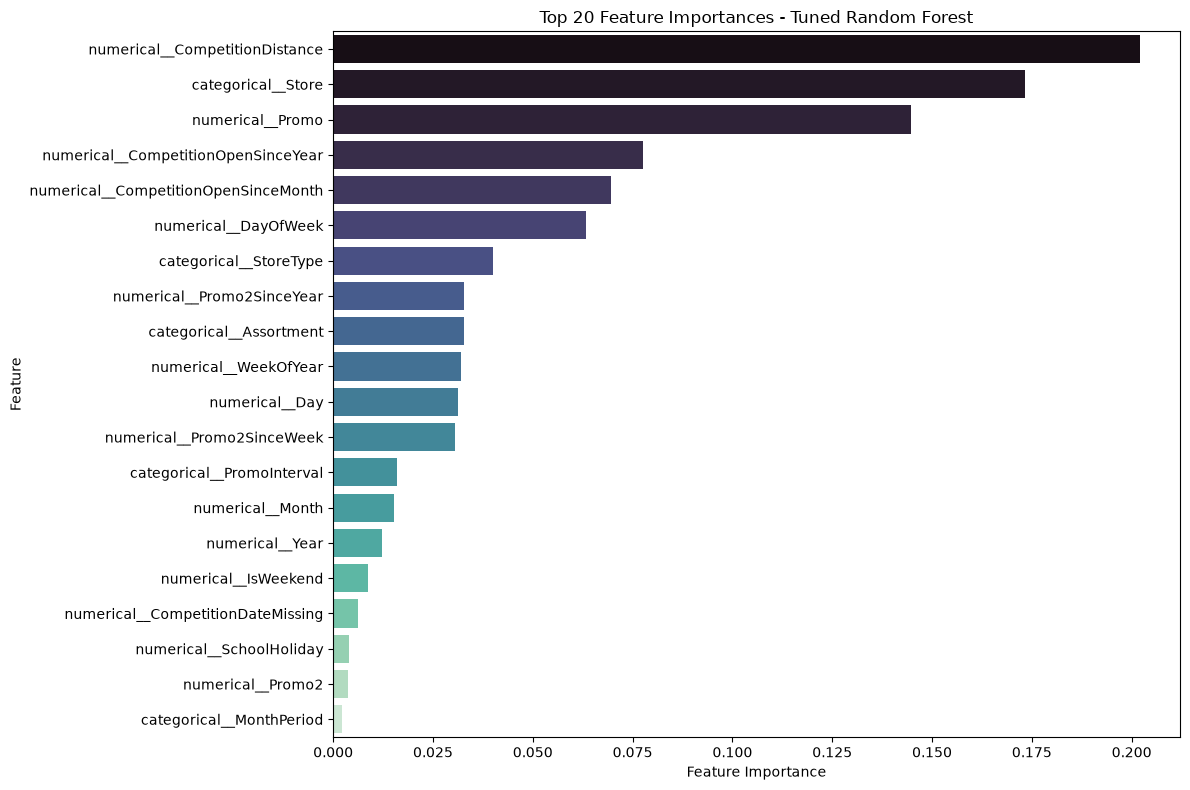

In [50]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=feature_importance.head(20),
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='mako',
    legend=False
)

plt.title('Top 20 Feature Importances - Tuned Random Forest')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

### **Serialising the Random Forest Models**

In [51]:
from datetime import datetime

In [52]:
# Create models directory if it does not exist
model_dir = "models"

os.makedirs(model_dir, exist_ok=True)

print("Model directory created successfully.")

Model directory created successfully.


In [53]:
# Generate timestamp
timestamp = datetime.now().strftime("%d-%m-%Y-%H-%M-%S-%f")

# Create model filename
rf_filename = f"random_forest_{timestamp}.pkl"

# Complete model path
rf_path = os.path.join(model_dir, rf_filename)

# Create model bundle
rf_bundle = {
    'model_name': 'Random Forest',
    'model': rf_model,
    'preprocessor': preprocessor,
    'feature_names': preprocessor.get_feature_names_out(),
    'metrics': {
        'MAE': mae,
        'RMSE': rmse,
        'RMSPE': rmspe,
        'R2': r2
    },
    'timestamp': timestamp
}

# Serialize model bundle
joblib.dump(rf_bundle, rf_path)

print("Original Random Forest model saved successfully.")
print("File:", rf_path)

# logger.info("Original Random Forest model saved: %s", rf_path)

Original Random Forest model saved successfully.
File: models\random_forest_15-11-2026-04-39-46-845874.pkl


## 📁 Random Forest – Model Serialization and Saving

Save the trained Random Forest model and its associated preprocessing components, feature information, and evaluation metrics into a single serialized file for future use and deployment.

- **Library:** Joblib
- **File Format:** Pickle (`.pkl`)
- **Storage Directory:** `models/`

The timestamp-based filename helps maintain separate versions of saved models and prevents accidental overwriting.

- The original Random Forest model was successfully serialized.
- The fitted preprocessing pipeline was included to maintain consistent transformations during future predictions.
- Evaluation metrics and feature names were saved alongside the model.
- The timestamp provides a reference for model version tracking.

**Next Step:** Save the tuned Random Forest model separately and retain its corresponding evaluation metrics for comparison and future model selection.

In [54]:
logger.info("=" * 70)
logger.info("ORIGINAL RANDOM FOREST MODEL SERIALIZATION")
logger.info("=" * 70)

logger.info("Model timestamp generated: %s", timestamp)
logger.info("Model filename: %s", rf_filename)
logger.info("Model directory: %s", model_dir)

logger.info("Random Forest model bundle created successfully.")
logger.info("Model name: %s", rf_bundle['model_name'])

logger.info(
    "Model bundle components: %s",
    list(rf_bundle.keys())
)

logger.info(
    "Model evaluation metrics stored: %s",
    rf_bundle['metrics']
)

logger.info("Serializing Random Forest model bundle using Joblib.")

logger.info("Original Random Forest model saved successfully.")
logger.info("Saved model path: %s", rf_path)

logger.info(
    "Saved model file size: %.2f MB",
    os.path.getsize(rf_path) / (1024 * 1024)
)

2026-11-15 04:44:02 | INFO | ======================================================================
2026-11-15 04:44:02 | INFO | ORIGINAL RANDOM FOREST MODEL SERIALIZATION
2026-11-15 04:44:02 | INFO | ======================================================================
2026-11-15 04:44:02 | INFO | Model timestamp generated: 15-11-2026-04-39-46-845874
2026-11-15 04:44:02 | INFO | Model filename: random_forest_15-11-2026-04-39-46-845874.pkl
2026-11-15 04:44:02 | INFO | Model directory: models
2026-11-15 04:44:02 | INFO | Random Forest model bundle created successfully.
2026-11-15 04:44:02 | INFO | Model name: Random Forest
2026-11-15 04:44:02 | INFO | Model bundle components: ['model_name', 'model', 'preprocessor', 'feature_names', 'metrics', 'timestamp']
2026-11-15 04:44:02 | INFO | Model evaluation metrics stored: {'MAE': 712.1764012190274, 'RMSE': np.float64(1038.7021544744728), 'RMSPE': np.float64(16.151054417766318), 'R2': 0.8749379680854126}
2026-11-15 04:44:02 | INFO | Serializi

In [55]:
# Generate timestamp
timestamp = datetime.now().strftime("%d-%m-%Y-%H-%M-%S-%f")

# Create model filename
tuned_rf_filename = f"tuned_random_forest_{timestamp}.pkl"

# Complete model path
tuned_rf_path = os.path.join(model_dir, tuned_rf_filename)

# Create model bundle
tuned_rf_bundle = {
    'model_name': 'Tuned Random Forest',
    'model': rf_tuned,
    'preprocessor': preprocessor,
    'feature_names': preprocessor.get_feature_names_out(),
    'metrics': {
        'MAE': valid_mae_tuned,
        'RMSE': valid_rmse_tuned,
        'RMSPE': valid_rmspe_tuned,
        'R2': valid_r2_tuned
    },
    'timestamp': timestamp
}

# Serialize model bundle
joblib.dump(tuned_rf_bundle, tuned_rf_path)

print("Tuned Random Forest model saved successfully.")
print("File:", tuned_rf_path)

# logger.info("Tuned Random Forest model saved: %s", tuned_rf_path)

Tuned Random Forest model saved successfully.
File: models\tuned_random_forest_15-11-2026-04-44-24-985653.pkl


## 🎞️ Tuned Random Forest – Model Serialization and Saving

Save the optimised Random Forest model along with its fitted preprocessing pipeline, transformed feature names, validation metrics, and timestamp for future predictions and model deployment.

| Property | Value |
|---|---|
| Model | Tuned Random Forest |
| Format | Pickle (`.pkl`) |
| Storage Directory | `models/` |

- The optimised Random Forest estimator was successfully serialized.
- The fitted preprocessing pipeline was included for consistent future data transformations.
- Validation metrics were stored with the model for performance tracking.
- The timestamp-based filename supports model version management.
- The tuned model is saved separately from the original Random Forest, preserving both versions for comparison.

**Next Step:** Compare the saved baseline and tuned models, then proceed with evaluating additional regression algorithms to identify the best-performing sales forecasting model.

In [56]:
logger.info("=" * 70)
logger.info("TUNED RANDOM FOREST MODEL SERIALIZATION")
logger.info("=" * 70)

logger.info("Model timestamp generated: %s", timestamp)
logger.info("Model filename: %s", tuned_rf_filename)
logger.info("Model directory: %s", model_dir)

logger.info("Tuned Random Forest model bundle created successfully.")
logger.info("Model name: %s", tuned_rf_bundle['model_name'])

logger.info(
    "Model bundle components: %s",
    list(tuned_rf_bundle.keys())
)

logger.info(
    "Model evaluation metrics stored: %s",
    tuned_rf_bundle['metrics']
)

logger.info(
    "Tuned Random Forest model serialized successfully using Joblib."
)

logger.info("Saved model path: %s", tuned_rf_path)

logger.info(
    "Saved model file size: %.2f MB",
    os.path.getsize(tuned_rf_path) / (1024 * 1024)
)

2026-11-15 04:44:51 | INFO | ======================================================================
2026-11-15 04:44:51 | INFO | TUNED RANDOM FOREST MODEL SERIALIZATION
2026-11-15 04:44:51 | INFO | ======================================================================
2026-11-15 04:44:51 | INFO | Model timestamp generated: 15-11-2026-04-44-24-985653
2026-11-15 04:44:51 | INFO | Model filename: tuned_random_forest_15-11-2026-04-44-24-985653.pkl
2026-11-15 04:44:51 | INFO | Model directory: models
2026-11-15 04:44:51 | INFO | Tuned Random Forest model bundle created successfully.
2026-11-15 04:44:52 | INFO | Model name: Tuned Random Forest
2026-11-15 04:44:52 | INFO | Model bundle components: ['model_name', 'model', 'preprocessor', 'feature_names', 'metrics', 'timestamp']
2026-11-15 04:44:52 | INFO | Model evaluation metrics stored: {'MAE': 685.0175759784112, 'RMSE': np.float64(965.2328608814722), 'RMSPE': np.float64(14.782090623145985), 'R2': 0.8920040141540425}
2026-11-15 04:44:52 | IN

In [57]:
# Load tuned Random Forest model
loaded_rf_bundle = joblib.load(tuned_rf_path)

# Extract model and preprocessor
loaded_rf_model = loaded_rf_bundle['model']
loaded_preprocessor = loaded_rf_bundle['preprocessor']

print("Model loaded successfully!")
print("Model name:", loaded_rf_bundle['model_name'])
print("Saved timestamp:", loaded_rf_bundle['timestamp'])

print("\nStored evaluation metrics:")
print(loaded_rf_bundle['metrics'])

Model loaded successfully!
Model name: Tuned Random Forest
Saved timestamp: 15-11-2026-04-44-24-985653

Stored evaluation metrics:
{'MAE': 685.0175759784112, 'RMSE': np.float64(965.2328608814722), 'RMSPE': np.float64(14.782090623145985), 'R2': 0.8920040141540425}


## ⬇️ Tuned Random Forest – Model Loading and Verification

Load the previously saved Tuned Random Forest model bundle and verify that the model, preprocessing pipeline, and stored evaluation metrics are accessible without retraining.

### Stored Evaluation Metrics

| Metric | Saved Value |
|---|---:|
| **MAE** | 685.02 |
| **RMSE** | 965.23 |
| **RMSPE** | 14.78% |
| **R² Score** | 0.8920 |

### 🗝️ Key Findings

- The saved Tuned Random Forest model was successfully restored.
- The associated preprocessing pipeline was retrieved.
- All four validation metrics were recovered correctly.
- The loaded model retains its previously evaluated performance without requiring another training session.

### Conclusion

The model serialization and loading process was completed successfully. The restored model and preprocessing pipeline are ready for subsequent prediction tasks, provided that incoming data follows the same feature structure used during training.

**Next Step:** Use the loaded preprocessing pipeline to transform the testing dataset and generate sales predictions with the restored Tuned Random Forest model.

In [58]:
logger.info("=" * 70)
logger.info("TUNED RANDOM FOREST MODEL LOADING")
logger.info("=" * 70)

logger.info("Loading tuned Random Forest model from: %s", tuned_rf_path)

logger.info("Tuned Random Forest model bundle loaded successfully.")

logger.info(
    "Loaded model name: %s",
    loaded_rf_bundle['model_name']
)

logger.info(
    "Loaded model type: %s",
    type(loaded_rf_model).__name__
)

logger.info(
    "Loaded preprocessor type: %s",
    type(loaded_preprocessor).__name__
)

logger.info(
    "Saved model timestamp: %s",
    loaded_rf_bundle['timestamp']
)

logger.info(
    "Stored evaluation metrics: %s",
    loaded_rf_bundle['metrics']
)

logger.info(
    "Stored feature count: %d",
    len(loaded_rf_bundle['feature_names'])
)

2026-11-15 04:46:13 | INFO | ======================================================================
2026-11-15 04:46:13 | INFO | TUNED RANDOM FOREST MODEL LOADING
2026-11-15 04:46:13 | INFO | ======================================================================
2026-11-15 04:46:13 | INFO | Loading tuned Random Forest model from: models\tuned_random_forest_15-11-2026-04-44-24-985653.pkl
2026-11-15 04:46:13 | INFO | Tuned Random Forest model bundle loaded successfully.
2026-11-15 04:46:13 | INFO | Loaded model name: Tuned Random Forest
2026-11-15 04:46:13 | INFO | Loaded model type: RandomForestRegressor
2026-11-15 04:46:13 | INFO | Loaded preprocessor type: ColumnTransformer
2026-11-15 04:46:13 | INFO | Saved model timestamp: 15-11-2026-04-44-24-985653
2026-11-15 04:46:13 | INFO | Stored evaluation metrics: {'MAE': 685.0175759784112, 'RMSE': np.float64(965.2328608814722), 'RMSPE': np.float64(14.782090623145985), 'R2': 0.8920040141540425}
2026-11-15 04:46:13 | INFO | Stored feature coun

In [54]:
# Generate predictions using loaded model
loaded_predictions = loaded_rf_model.predict(X_valid_processed)

# Display first 10 predictions
print("First 10 validation predictions:")
print(loaded_predictions[:10])

First 10 validation predictions:
[ 6142.80185219  7146.18023811  9346.39544161 12361.28435159
  6639.69420369  6887.06039656 11567.08671472  7293.08200436
  9368.49934957  6601.8054614 ]


## 🎄 Tuned Random Forest – Validation Predictions

Generate sales predictions for the validation dataset using the previously saved and reloaded Tuned Random Forest model to verify its prediction capability on unseen observations.

### 🔑 Key Findings

- The loaded Tuned Random Forest model successfully generated predictions for validation observations.
- Predicted sales range from approximately **6,142.80 to 12,361.28** across the first 10 records.
- The model produces continuous numerical outputs suitable for the sales forecasting task.
- Successful prediction confirms that the saved estimator can be reused without retraining.

### Conclusion

The Tuned Random Forest model successfully generated validation predictions after being reloaded from its serialized bundle. This confirms that the model restoration and inference workflow is functioning as expected.

**Next Step:** Compare predicted sales against actual validation sales to inspect individual prediction errors and identify potential underprediction or overprediction patterns.

In [59]:
# Select the same features used during model training
X_test = test_df[X.columns].copy()

print("Test feature shape:", X_test.shape)
print("Training feature shape:", X.shape)

Test feature shape: (41088, 22)
Training feature shape: (1017209, 22)


In [60]:
assert list(X_test.columns) == list(X.columns), \
    "Training and test feature columns do not match!"

assert X_test.isnull().sum().sum() == 0, \
    "Missing values found in test features!"

In [61]:
# Transform test features using the existing fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("Processed test shape:", X_test_processed.shape)

Processed test shape: (41088, 22)


d:\Digicrome AI\Internship\Nexthikes IT\virtual\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Digicrome AI\Internship\Nexthikes IT\virtual\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(


In [63]:
# Identify open and closed stores
test_open_mask = X_test['Open'].eq(1).to_numpy()

# Initialize predictions with zero
test_predictions = np.zeros(len(X_test))

# Predict only for open stores
test_predictions[test_open_mask] = loaded_rf_model.predict(
    X_test_processed[test_open_mask]
)

print("Total test records:", len(test_predictions))
print("Open store records:", test_open_mask.sum())
print("Closed store records:", (~test_open_mask).sum())
print("Total predictions:", len(test_predictions))

d:\Digicrome AI\Internship\Nexthikes IT\virtual\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Digicrome AI\Internship\Nexthikes IT\virtual\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Digicrome AI\Internship\Nexthikes IT\virtual\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Digicrome AI\Internship\Next

Total test records: 41088
Open store records: 35104
Closed store records: 5984
Total predictions: 41088


## 🖲️ Testing Dataset – Store Status and Prediction Coverage

Inspect the testing dataset's store operating status and verify that the sales prediction process generates predictions for all test records.

### 🙇‍♀️Testing Dataset Overview

| Metric | Records | Percentage |
|---|---:|---:|
| Total Test Records | 41,088 | 100.00% |
| Open Stores (`Open = 1`) | 35,104 | 85.43% |
| Closed Stores (`Open = 0`) | 5,984 | 14.57% |
| **Total Predictions Generated** | **41,088** | **100.00%** |

### 🔑 Key Findings

- **Complete prediction coverage:** Predictions were generated for all 41,088 testing records.
- **Open stores:** 35,104 observations represent stores operating during the testing period.
- **Closed stores:** 5,984 observations represent store closures and should have zero sales.
- **Prediction alignment:** The total number of predictions matches the total number of test records.

### Conclusion

The testing dataset contains 41,088 store-day observations, of which approximately 85.43% belong to open stores and 14.57% to closed stores.

The prediction process successfully covers the entire testing dataset. Separating open and closed stores ensures that the model's predictions follow the operating-status information available

In [64]:
logger.info("=" * 70)
logger.info("TEST DATA PREDICTION")
logger.info("=" * 70)

logger.info("Identifying open and closed stores in test data.")

logger.info("Total test records: %d", len(X_test))
logger.info("Open store records: %d", test_open_mask.sum())
logger.info("Closed store records: %d", (~test_open_mask).sum())

logger.info("Initializing test predictions with zero.")

logger.info(
    "Generating predictions only for open stores."
)

logger.info(
    "Open store input shape: %s",
    X_test_processed[test_open_mask].shape
)

logger.info(
    "Total predictions generated: %d",
    len(test_predictions)
)

logger.info(
    "Predictions assigned to closed stores: %d",
    np.sum(test_predictions[~test_open_mask] == 0)
)

logger.info(
    "Open store prediction count: %d",
    np.count_nonzero(test_predictions[test_open_mask])
)

logger.info(
    "Test prediction minimum: %.2f",
    test_predictions.min()
)

logger.info(
    "Test prediction maximum: %.2f",
    test_predictions.max()
)

2026-11-15 04:52:49 | INFO | ======================================================================
2026-11-15 04:52:49 | INFO | TEST DATA PREDICTION
2026-11-15 04:52:49 | INFO | ======================================================================
2026-11-15 04:52:49 | INFO | Identifying open and closed stores in test data.
2026-11-15 04:52:49 | INFO | Total test records: 41088
2026-11-15 04:52:49 | INFO | Open store records: 35104
2026-11-15 04:52:49 | INFO | Closed store records: 5984
2026-11-15 04:52:49 | INFO | Initializing test predictions with zero.
2026-11-15 04:52:49 | INFO | Generating predictions only for open stores.
2026-11-15 04:52:49 | INFO | Open store input shape: (35104, 22)
2026-11-15 04:52:49 | INFO | Total predictions generated: 41088
2026-11-15 04:52:49 | INFO | Predictions assigned to closed stores: 5984
2026-11-15 04:52:49 | INFO | Open store prediction count: 35104
2026-11-15 04:52:49 | INFO | Test prediction minimum: 0.00
2026-11-15 04:52:49 | INFO | Test pre

In [65]:
print("Prediction Summary")
print("-" * 45)

print("Minimum Sales:", test_predictions.min())
print("Maximum Sales:", test_predictions.max())
print("Mean Sales:", test_predictions.mean())
print("Median Sales:", np.median(test_predictions))

print("\nMissing Predictions:", np.isnan(test_predictions).sum())
print("Infinite Predictions:", np.isinf(test_predictions).sum())
print("Zero Predictions:", (test_predictions == 0).sum())

Prediction Summary
---------------------------------------------
Minimum Sales: 0.0
Maximum Sales: 30571.898544220458
Mean Sales: 5981.709713692225
Median Sales: 6051.079245680033

Missing Predictions: 0
Infinite Predictions: 0
Zero Predictions: 5984


## 🎋 Test Dataset – Final Prediction Summary

Perform a statistical and quality assessment of the generated sales predictions to verify their distribution, completeness, and consistency before preparing the final submission file.

| Statistical Measure | Predicted Sales |
|---|---:|
| **Minimum Sales** | 0.00 |
| **Maximum Sales** | 30,571.90 |
| **Mean Sales** | 5,981.71 |
| **Median Sales** | 6,051.08 |

### ✔️ Prediction Quality Checks

| Validation Check | Result | Status |
|---|---:|---|
| Missing Predictions | 0 | <badge color="success">Passed</badge> |
| Infinite Predictions | 0 | <badge color="success">Passed</badge> |
| Zero Predictions | 5,984 | <badge color="success">Verified</badge> |
| Total Predictions | 41,088 | <badge color="success">Complete</badge> |

### 🔑 Key Findings

- **Prediction completeness:** All 41,088 test records have valid predictions.
- **No missing values:** The prediction array contains no missing values.
- **No infinite values:** All predictions are finite numerical values.
- **Closed-store consistency:** Exactly 5,984 zero predictions correspond to the closed-store records.
- **Sales distribution:** The mean predicted sales are 5,981.71, while the median is 6,051.08.
- **Prediction range:** Predicted sales range from zero to approximately 30,571.90.

### Conclusion

The final prediction array passes the basic data-quality checks. All test records have valid numerical predictions, and the zero predictions correctly account for the 5,984 closed-store observations.

The prediction dataset is ready for final submission preparation, subject to verifying record alignment and the required submission format.

**Next Step:** Combine the predicted sales with the original test dataset's `Id` column and export the final submission CSV.

In [66]:
logger.info("=" * 70)
logger.info("TEST PREDICTION SUMMARY")
logger.info("=" * 70)

logger.info("Minimum predicted sales: %.2f", test_predictions.min())
logger.info("Maximum predicted sales: %.2f", test_predictions.max())
logger.info("Mean predicted sales: %.2f", test_predictions.mean())
logger.info("Median predicted sales: %.2f", np.median(test_predictions))

logger.info(
    "Missing predictions: %d",
    np.isnan(test_predictions).sum()
)

logger.info(
    "Infinite predictions: %d",
    np.isinf(test_predictions).sum()
)

logger.info(
    "Zero predictions: %d",
    (test_predictions == 0).sum()
)

logger.info(
    "Total prediction records: %d",
    len(test_predictions)
)

2026-11-15 04:53:58 | INFO | ======================================================================
2026-11-15 04:53:58 | INFO | TEST PREDICTION SUMMARY
2026-11-15 04:53:58 | INFO | ======================================================================
2026-11-15 04:53:58 | INFO | Minimum predicted sales: 0.00
2026-11-15 04:53:58 | INFO | Maximum predicted sales: 30571.90
2026-11-15 04:53:58 | INFO | Mean predicted sales: 5981.71
2026-11-15 04:53:58 | INFO | Median predicted sales: 6051.08
2026-11-15 04:53:58 | INFO | Missing predictions: 0
2026-11-15 04:53:58 | INFO | Infinite predictions: 0
2026-11-15 04:53:58 | INFO | Zero predictions: 5984
2026-11-15 04:53:58 | INFO | Total prediction records: 41088


In [68]:
# Generate validation predictions
valid_predictions = loaded_rf_model.predict(X_valid_open)

# Calculate absolute prediction errors
absolute_errors = np.abs(
    np.asarray(y_valid_open) - valid_predictions
)

print("Validation prediction analysis")
print("-" * 45)
print("Validation records:", len(y_valid_open))
print("Mean absolute error:", absolute_errors.mean())
print("95th percentile error:", np.percentile(absolute_errors, 95))

d:\Digicrome AI\Internship\Nexthikes IT\virtual\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Digicrome AI\Internship\Nexthikes IT\virtual\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Digicrome AI\Internship\Nexthikes IT\virtual\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Digicrome AI\Internship\Next

Validation prediction analysis
---------------------------------------------
Validation records: 30188
Mean absolute error: 685.0175759784112
95th percentile error: 1965.4483894541647


## 🎭 Validation Prediction – Error Distribution Analysis
Analyse the distribution of prediction errors on the validation dataset to understand the model's typical prediction accuracy and the magnitude of larger errors.

| Evaluation Metric | Value |
|---|---:|
| **Validation Records** | 30,188 |
| **Mean Absolute Error (MAE)** | 685.02 |
| **95th Percentile Absolute Error** | 1,965.45 |

### 🗝️ Key Findings

- **Average prediction error:** The model has an MAE of 685.02, indicating an average absolute difference of approximately 685 sales units between predicted and actual sales.
- **95th percentile error:** Approximately 95% of validation observations have absolute prediction errors of 1,965.45 or less.
- **Larger prediction errors:** The remaining 5% of observations have errors above this threshold, highlighting cases where the model struggles to predict sales accurately.
- **Validation coverage:** The analysis includes 30,188 validation records, corresponding to the open-store observations used for model evaluation.

### Conclusion

The Tuned Random Forest model demonstrates an average absolute prediction error of 685.02 sales units. However, the 95th percentile error of 1,965.45 indicates that a smaller proportion of predictions have considerably larger deviations.

This suggests that while the model performs reasonably well across most validation observations, further investigation of high-error cases may reveal opportunities for improvement.

**Next Step:** Examine the observations with the largest absolute prediction errors to identify whether specific stores, promotional periods, weekdays, or seasonal patterns contribute to poor predictions.

In [69]:
logger.info("=" * 70)
logger.info("VALIDATION PREDICTION ERROR ANALYSIS")
logger.info("=" * 70)

logger.info("Generating validation predictions using loaded Random Forest model.")

logger.info(
    "Validation input shape: %s",
    X_valid_open.shape
)

logger.info(
    "Number of validation predictions: %d",
    len(valid_predictions)
)

logger.info(
    "Number of actual validation records: %d",
    len(y_valid_open)
)

logger.info(
    "Mean absolute prediction error: %.2f",
    absolute_errors.mean()
)

logger.info(
    "95th percentile absolute error: %.2f",
    np.percentile(absolute_errors, 95)
)

logger.info(
    "Maximum absolute prediction error: %.2f",
    absolute_errors.max()
)

logger.info(
    "Minimum absolute prediction error: %.2f",
    absolute_errors.min()
)

2026-11-15 04:58:57 | INFO | ======================================================================
2026-11-15 04:58:57 | INFO | VALIDATION PREDICTION ERROR ANALYSIS
2026-11-15 04:58:57 | INFO | ======================================================================
2026-11-15 04:58:57 | INFO | Generating validation predictions using loaded Random Forest model.
2026-11-15 04:58:58 | INFO | Validation input shape: (30188, 22)
2026-11-15 04:58:58 | INFO | Number of validation predictions: 30188
2026-11-15 04:58:58 | INFO | Number of actual validation records: 30188
2026-11-15 04:58:58 | INFO | Mean absolute prediction error: 685.02
2026-11-15 04:58:58 | INFO | 95th percentile absolute error: 1965.45
2026-11-15 04:58:58 | INFO | Maximum absolute prediction error: 19325.66
2026-11-15 04:58:58 | INFO | Minimum absolute prediction error: 0.03


In [70]:
# Desired prediction interval coverage
confidence_level = 0.95

# Number of validation observations
n = len(absolute_errors)

# Calculate finite-sample conformal quantile
quantile_level = np.ceil(
    (n + 1) * confidence_level
) / n

# Calculate calibrated error threshold
error_threshold = np.quantile(
    absolute_errors,
    quantile_level,
    method='higher'
)

print("95% Calibrated Error Threshold:",
      round(error_threshold, 2))

95% Calibrated Error Threshold: 1966.54


## 🖋️ Conformal Prediction – 95% Calibrated Error Threshold

Calculate a calibrated absolute-error threshold using validation residuals to estimate prediction uncertainty and construct prediction intervals for future sales predictions.

| Parameter | Value |
|---|---:|
| Confidence Level | 95% |
| Validation Observations (`n`) | 30,188 |
| Quantile Method | Finite-sample conformal quantile |
| Quantile Selection | `method='higher'` |
| Calibrated Error Threshold | **1,966.54** |

### 🧰 Methodology

The calibration threshold was calculated using the absolute prediction errors from the validation dataset.

The finite-sample quantile level is:

$[
q = \frac{\lceil(n+1)\times 0.95\rceil}{n}
]$

The calibrated error threshold is then obtained from the corresponding empirical quantile of the absolute validation errors.

### 🔑 Key Findings

- The calibrated error threshold is **1,966.54 sales units**.
- This value represents the estimated error margin used to construct 95% conformal prediction intervals.
- The threshold is slightly higher than the previously calculated 95th percentile error of 1,965.45 because the conformal calculation applies a finite-sample adjustment.
- The threshold can be applied symmetrically around each point prediction to construct prediction intervals.

For a predicted sales value \(\hat{y}\), the prediction interval is:


$[\hat{y}-1,966.54,\ \hat{y}+1,966.54]$


For example, if the predicted sales are 6,000:

$[4,033.46,\ 7,966.54]$

### Conclusion

The conformal calibration procedure produced an error threshold of 1,966.54 sales units for the 95% target coverage level. This provides an uncertainty estimate alongside the model's point predictions.

**Next Step:** Apply the calibrated threshold to validation and test predictions to construct prediction intervals and evaluate their actual coverage on the validation dataset.

In [71]:
logger.info("=" * 70)
logger.info("CONFORMAL PREDICTION INTERVAL CALIBRATION")
logger.info("=" * 70)

logger.info(
    "Desired prediction interval coverage: %.2f%%",
    confidence_level * 100
)

logger.info(
    "Number of validation observations: %d",
    n
)

logger.info(
    "Calculated conformal quantile level: %.6f",
    quantile_level
)

logger.info(
    "Calibrated absolute error threshold: %.2f",
    error_threshold
)

logger.info(
    "Quantile calculation method: higher"
)

logger.info(
    "Conformal prediction interval calibration completed successfully."
)

2026-11-15 05:00:25 | INFO | ======================================================================
2026-11-15 05:00:25 | INFO | CONFORMAL PREDICTION INTERVAL CALIBRATION
2026-11-15 05:00:25 | INFO | ======================================================================
2026-11-15 05:00:25 | INFO | Desired prediction interval coverage: 95.00%
2026-11-15 05:00:25 | INFO | Number of validation observations: 30188
2026-11-15 05:00:25 | INFO | Calculated conformal quantile level: 0.950046
2026-11-15 05:00:25 | INFO | Calibrated absolute error threshold: 1966.54
2026-11-15 05:00:25 | INFO | Quantile calculation method: higher
2026-11-15 05:00:25 | INFO | Conformal prediction interval calibration completed successfully.


In [62]:
# Initialize interval bounds
lower_bounds = np.zeros(len(test_predictions))
upper_bounds = np.zeros(len(test_predictions))

# Calculate intervals for open stores
lower_bounds[test_open_mask] = np.maximum(
    test_predictions[test_open_mask] - error_threshold,
    0
)

upper_bounds[test_open_mask] = (
    test_predictions[test_open_mask] + error_threshold
)

# Closed stores have zero sales
lower_bounds[~test_open_mask] = 0
upper_bounds[~test_open_mask] = 0

## 🦯 Conformal Prediction – Test Dataset Prediction Intervals

Construct 95% conformal prediction intervals for the testing dataset using the calibrated error threshold of 1,966.54 sales units.

The intervals provide an estimated range around each point prediction to represent potential uncertainty in the sales forecasts.

### 🔧 Interval Calculation Methodology

The prediction intervals were calculated separately for open and closed stores.

**Open Stores (`Open = 1`)**

The calibrated error threshold is added to and subtracted from each point prediction.

$Lower=\max(0,\hat{y}-1,966.54)$

$Upper=\hat{y}+1,966.54$

The lower bound is restricted to zero because negative sales are not meaningful.

**Closed Stores (`Open = 0`)**

Since closed stores are expected to generate zero sales:

$(Lower=0,\qquad Upper=0)$

### 🗄️ Prediction Interval Configuration

| Parameter | Value |
|---|---:|
| Target Coverage Level | 95% |
| Calibrated Error Threshold | 1,966.54 |
| Open-Store Interval | Prediction ± 1,966.54 |
| Minimum Lower Bound | 0 |
| Closed-Store Lower Bound | 0 |
| Closed-Store Upper Bound | 0 |

### 🔑 Key Findings

- Prediction intervals are generated for all open-store observations.
- The same calibrated error threshold is applied consistently across open stores.
- Negative lower bounds are prevented using a zero minimum.
- Closed stores retain exact zero lower and upper bounds.
- The interval arrays preserve

In [63]:
valid_lower = np.maximum(
    valid_predictions - error_threshold,
    0
)

valid_upper = valid_predictions + error_threshold

covered = (
    (np.asarray(y_valid_open) >= valid_lower) &
    (np.asarray(y_valid_open) <= valid_upper)
)

coverage = covered.mean() * 100

print(f"Target Coverage: 95%")
print(f"Observed Validation Coverage: {coverage:.2f}%")

Target Coverage: 95%
Observed Validation Coverage: 95.01%


In [64]:
# Actual validation sales
actual = np.asarray(y_valid_open)

# Check whether actual sales fall within the interval
covered = (
    (actual >= valid_lower) &
    (actual <= valid_upper)
)

# Calculate interval coverage
coverage = np.mean(covered) * 100

# Calculate average interval width
average_width = np.mean(valid_upper - valid_lower)

# Calculate interval evaluation metrics
print("PREDICTION INTERVAL EVALUATION")
print("-" * 45)

print(f"Target Coverage:       95.00%")
print(f"Observed Coverage:     {coverage:.2f}%")
print(f"Average Interval Width: {average_width:.2f}")
print(f"Error Threshold:        {error_threshold:.2f}")

PREDICTION INTERVAL EVALUATION
---------------------------------------------
Target Coverage:       95.00%
Observed Coverage:     95.01%
Average Interval Width: 3931.97
Error Threshold:        1966.54


## 📲 Conformal Prediction – Prediction Interval Evaluation

Evaluate the effectiveness of the constructed 95% conformal prediction intervals by comparing the observed coverage against the target coverage and analysing the average interval width.

| Evaluation Metric | Result |
|---|---:|
| **Target Coverage** | 95.00% |
| **Observed Coverage** | 95.01% |
| **Average Interval Width** | 3,931.97 |
| **Calibrated Error Threshold** | 1,966.54 |

### 🔑 Key Findings

- **Coverage accuracy:** The observed coverage of 95.01% closely matches the target coverage of 95%.
- **Coverage difference:** The difference between target and observed coverage is only 0.01 percentage points.
- **Interval width:** The average prediction interval width is 3,931.97 sales units, representing the uncertainty range around the point predictions.
- **Calibration effectiveness:** The calibrated error threshold successfully produces validation intervals with coverage close to the desired confidence level.

### 🤵 Overall Interpretation

The conformal prediction approach achieves an observed coverage of 95.01%, indicating that approximately 95 out of every 100 actual validation sales values fall within their corresponding prediction intervals.

The results suggest that the calibration procedure provides a useful measure of prediction uncertainty alongside the Tuned Random Forest point forecasts.

### Conclusion

The prediction interval evaluation demonstrates that the calibrated intervals closely achieve the intended 95% validation coverage.

The Tuned Random Forest forecasting workflow now provides both:
- **Point predictions:** Estimated sales values.
- **Prediction intervals:** Estimated ranges representing uncertainty around those predictions.

This adds an uncertainty assessment to the sales forecasting model rather than relying exclusively on point predictions.

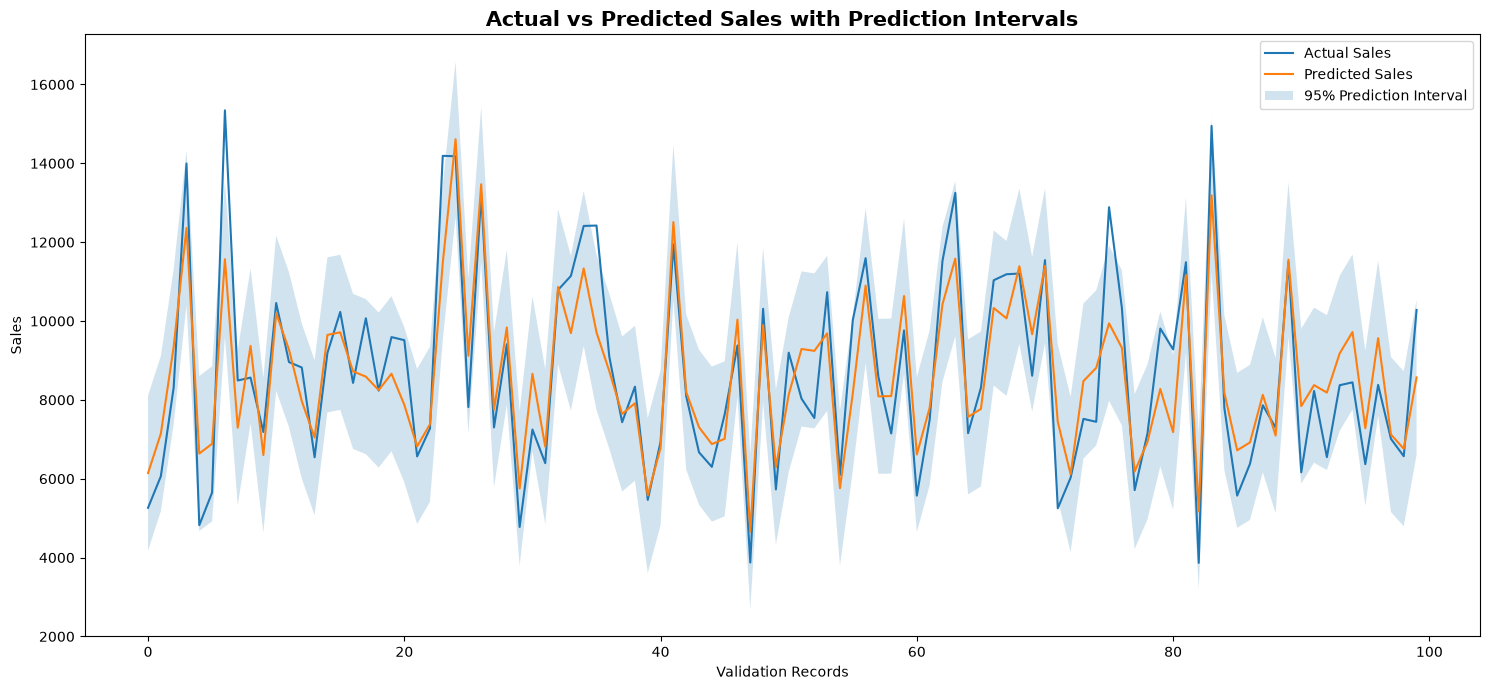

In [65]:
# Create a sample for visualization
plot_df = pd.DataFrame({
    'Actual': actual,
    'Predicted': valid_predictions,
    'Lower': valid_lower,
    'Upper': valid_upper
}).head(100)

plt.figure(figsize=(15, 7))

x = np.arange(len(plot_df))

plt.plot(
    x,
    plot_df['Actual'],
    label='Actual Sales',
    linewidth=1.5
)

plt.plot(
    x,
    plot_df['Predicted'],
    label='Predicted Sales',
    linewidth=1.5
)

plt.fill_between(
    x,
    plot_df['Lower'],
    plot_df['Upper'],
    alpha=0.2,
    label='95% Prediction Interval'
)

plt.title(
    'Actual vs Predicted Sales with Prediction Intervals',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Validation Records')
plt.ylabel('Sales')

plt.legend()
plt.tight_layout()
plt.show()

## 🤹 Actual vs. Predicted Sales – Validation Analysis with 95% Prediction Intervals

Visualise and compare actual sales against the Tuned Random Forest predictions for the validation dataset, including the calibrated 95% prediction intervals, to assess prediction accuracy and uncertainty.

The visualisation presents three key elements:

- **Actual Sales (Blue):** The observed sales values from the validation dataset.
- **Predicted Sales (Orange):** Sales estimates generated by the Tuned Random Forest model.
- **95% Prediction Interval (Shaded Region):** The estimated range within which actual sales are expected to fall.

### 🗝️ Key Findings

- **Prediction alignment:** The predicted sales generally follow the movement and direction of actual sales, indicating that the model captures important sales patterns.
- **Peak sales:** The model captures several major sales peaks, although some high-sales observations are underpredicted.
- **Lower sales periods:** Predictions generally remain close to actual values during relatively stable sales periods.
- **Prediction uncertainty:** The shaded prediction intervals provide a relatively broad range around the point forecasts, reflecting uncertainty in individual predictions.
- **Variability:** Considerable fluctuations in actual sales indicate that store-level sales behaviour can be difficult to predict precisely.

### 🤵 Overall Interpretation

The Tuned Random Forest model demonstrates a reasonable ability to capture variations in sales across validation observations. However, differences between actual and predicted values are visible, particularly around some sharp sales fluctuations.

The prediction intervals add an uncertainty dimension to the forecasts, helping assess the range of possible sales outcomes rather than relying exclusively on point predictions.

### Conclusion

The visual comparison supports the quantitative evaluation of the Tuned Random Forest model, which achieved:

| Evaluation Metric | Result |
|---|---:|
| Validation MAE | 685.02 |
| Validation RMSE | 965.23 |
| Validation R² | 89.20% |
| Validation RMSPE | 14.78% |
| Observed Interval Coverage | 95.01% |

Overall, the model provides a promising sales forecasting solution, with reasonably strong predictive performance and calibrated prediction intervals.

In [ ]:
# Log completion before closing handlers
logger.info("=" * 70)
logger.info("Releasing logging resources")
logger.info("Model logging session closed successfully")
logger.info("=" * 70)

# Flush and close all handlers
for handler in logger.handlers[:]:
    handler.flush()
    handler.close()
    logger.removeHandler(handler)

# Release logger reference
logging.shutdown()

print("All logging resources released successfully.")